In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import mean_squared_error
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet, MultiTaskLasso, MultiTaskElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.kernel_ridge import KernelRidge
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.utils import resample
from sklearn.base import clone
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.feature_selection import f_regression, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

import holidays

In [4]:
import warnings
warnings.filterwarnings("ignore")

In [5]:
daily_metrics = pd.read_csv('../src/data/processed/daily_metrics.csv', parse_dates=['date'])
dcl_prices = pd.read_csv('../src/data/processed/gb_dcl_prices_gbp_per_mw_per_hour.csv', parse_dates=['dtutc'])


In [6]:
daily_metrics.columns

Index(['date', 'demand_National Demand Forecast (NDF) - GB (MW)_mean',
       'demand_National Demand Forecast (NDF) - GB (MW)_max',
       'demand_National Demand Forecast (NDF) - GB (MW)_min',
       'demand_National Demand Forecast (NDF) - GB (MW)_spread',
       'demand_National Demand Forecast (NDF) - GB (MW)_std',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_std',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_rolling_std_7d',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_price_range',
       'price_Price average forecast ECMWF ENS United

In [7]:
dcl_prices['date'] = dcl_prices['dtutc'].dt.date
dcl_prices['time_block'] = dcl_prices['dtutc'].dt.hour // 4 + 1
dcl_prices_pivot = dcl_prices.pivot_table(index='date', columns='time_block', values='dcl_price', aggfunc='first').reset_index()
dcl_prices_pivot.columns = ['date'] + [f'price_{i}' for i in range(1, 7)]

In [8]:
daily_metrics['date'] = pd.to_datetime(daily_metrics['date'])
dcl_prices_pivot['date'] = pd.to_datetime(dcl_prices_pivot['date'])

data = pd.merge(daily_metrics, dcl_prices_pivot, on='date', how='inner')

In [9]:
def add_features(data):
    uk_holidays = holidays.UK()
    data['is_holiday'] = data['date'].dt.date.apply(lambda x: x in uk_holidays)
    data['day_of_week'] = data['date'].dt.dayofweek
#     data['month'] = data['date'].dt.month
    data['season'] = data['date'].dt.month % 12 // 3 + 1 # Winter=1, Spring=2...
    data['hour_block'] = data['date'].dt.hour // 4  # 4-hour blocks
    data['price_lag_1d_block1'] = data.groupby('hour_block')['price_1'].shift(1)  # Lag for block 1

    return data

In [10]:
data = add_features(data)

In [11]:
feature_cols = [
    'demand_National Demand Forecast (NDF) - GB (MW)_mean',
    'demand_National Demand Forecast (NDF) - GB (MW)_max',
    'demand_National Demand Forecast (NDF) - GB (MW)_min',
    'demand_National Demand Forecast (NDF) - GB (MW)_spread',
    'demand_National Demand Forecast (NDF) - GB (MW)_std',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_std',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_rolling_std_7d',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_price_range',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_cv',
    'solar_solar_fc_meteo_mw_mean', 
    'solar_solar_fc_meteo_mw_max',
    'solar_solar_fc_meteo_mw_min', 
    'solar_solar_fc_meteo_mw_spread',
    'solar_solar_fc_meteo_mw_std', 
    'wind_wind_fc_meteo_mw_mean',
    'wind_wind_fc_meteo_mw_max', 
    'wind_wind_fc_meteo_mw_min',
    'wind_wind_fc_meteo_mw_spread', 
    'wind_wind_fc_meteo_mw_std',
#     'price_intraday_volatility', 
    'day_of_week', 
    'is_weekend', 
#     'month'
]

In [12]:
target_cols = [f'price_{i}' for i in range(1, 7)]

In [13]:
X = data[feature_cols]
y = data[target_cols]


In [14]:
# # podeli 
train_start_date = pd.Timestamp('2024-03-01')
train_end_date = pd.Timestamp('2024-08-31')
test_start_date = pd.Timestamp('2024-09-01')
test_end_date = pd.Timestamp('2024-09-30')


In [15]:
X_train = X[data['date'] <= train_end_date]
y_train = y[data['date'] <= train_end_date]
X_test = X[(data['date'] >= test_start_date) & (data['date'] <= test_end_date)]
y_test = y[(data['date'] >= test_start_date) & (data['date'] <= test_end_date)]

In [19]:
X_train['date']

KeyError: 'date'

In [23]:
y_train = y_train.fillna(y_train.mean())
y_test = y_test.fillna(y_train.mean())

# Feature selection functions


In [24]:
def univariate_feature_selection(X, y, k=20):
    missing_count = X.isnull().sum().sum()
    if missing_count > 0:
        print(f"Imputing {missing_count} missing values before feature selection")
        
        imputer = SimpleImputer(strategy='mean')
        X_imputed = pd.DataFrame(imputer.fit_transform(X), columns=X.columns)
        
        selector = SelectKBest(score_func=f_regression, k=k)
        X_selected = selector.fit_transform(X_imputed, y.iloc[:, 0])
        selected_features = X_imputed.columns[selector.get_support()]
    else:
        selector = SelectKBest(score_func=f_regression, k=k)
        X_selected = selector.fit_transform(X, y.iloc[:, 0])
        selected_features = X.columns[selector.get_support()]
    
    return X_selected, selected_features


In [25]:
def recursive_feature_elimination(X, y, estimator=LinearRegression(), n_features=20):
    selector = RFE(estimator=estimator, n_features_to_select=n_features)
    X_selected = selector.fit_transform(X, y.iloc[:, 0]) 
    selected_features = X.columns[selector.get_support()]
    return X_selected, selected_features


In [26]:
y_train = y_train.fillna(y_train.mean())
y_test = y_test.fillna(y_train.mean())
X_train = X_train.fillna(X_train.mean())
X_test = X_test.fillna(X_test.mean())

In [27]:
X_train_selected_uni, selected_features_uni = univariate_feature_selection(X_train, y_train)
X_train_selected_rfe, selected_features_rfe = recursive_feature_elimination(X_train, y_train)

print("Selected features (Univariate):", selected_features_uni)
print("Selected features (RFE):", selected_features_rfe)

X_train_selected = X_train[selected_features_uni]
X_test_selected = X_test[selected_features_uni]


Selected features (Univariate): Index(['demand_National Demand Forecast (NDF) - GB (MW)_mean',
       'demand_National Demand Forecast (NDF) - GB (MW)_max',
       'demand_National Demand Forecast (NDF) - GB (MW)_min',
       'demand_National Demand Forecast (NDF) - GB (MW)_spread',
       'demand_National Demand Forecast (NDF) - GB (MW)_std',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_std',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_rolling_std_7d',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_price_range',
       'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_cv',
       'solar_solar_fc_meteo_mw

In [28]:
models = [
    ('Linear Regression', LinearRegression()),
    ('ElasticNet', ElasticNet()),
    ('Random Forest', RandomForestRegressor(random_state=42)),
    ('KNN', KNeighborsRegressor()),
    ('XGBoost', XGBRegressor(random_state=42)),

]


# Fix up defining evaluate_models


In [29]:
advanced_models = [
    ('Random Forest', RandomForestRegressor(random_state=42)),
    ('XGBoost', XGBRegressor(random_state=42)),
    ('Neural Network', MLPRegressor(random_state=42))
]

results_advanced = evaluate_all_models(X_train_selected, y_train, X_test_selected, y_test, advanced_models)
results_df_advanced = pd.DataFrame(results_advanced).sort_values('Total RMSE')
print("Advanced Model Evaluation Results:")
print(results_df_advanced)


Error evaluating Random Forest: name 'evaluate_model' is not defined
Error evaluating XGBoost: name 'evaluate_model' is not defined
Error evaluating Neural Network: name 'evaluate_model' is not defined


KeyError: 'Total RMSE'

In [ ]:
correlation_aware_models = [
    ('MultiTaskLasso', MultiTaskLasso(alpha=0.1, max_iter=10000)),
    ('MultiTaskElasticNet', MultiTaskElasticNet(alpha=0.1, l1_ratio=0.5, max_iter=10000)),
    ('RegressorChain (Ridge)', RegressorChain(Ridge(alpha=1.0)))
]

In [ ]:
all_models = models + correlation_aware_models


In [ ]:
def evaluate_model(model, X_train, y_train, X_test, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred, multioutput='raw_values'))
    return rmse

In [ ]:
def rolling_window_evaluation(X, y, model, window_size=100, step=1):
    n_samples = len(X)
    n_windows = max(1, (n_samples - window_size) // step)
    results = []
    for i in range(n_windows):
        train_start = i * step
        train_end = train_start + window_size
        X_train_win, y_train_win = X.iloc[train_start:train_end], y.iloc[train_start:train_end]
        X_test_win, y_test_win = X.iloc[train_end:train_end+1], y.iloc[train_end:train_end+1]
        model.fit(X_train_win, y_train_win)
        y_pred_win = model.predict(X_test_win)
        rmse_win = np.sqrt(mean_squared_error(y_test_win, y_pred_win))
        results.append(rmse_win)
    return np.mean(results)


# prediction intervals using bootstrap resampling


In [ ]:
def calculate_prediction_intervals(model, X_train, y_train, X_test, n_bootstraps=500, alpha=0.1):
    y_preds = np.zeros((n_bootstraps, X_test.shape[0], y_train.shape[1]))
    
    for i in range(n_bootstraps):
        X_resampled, y_resampled = resample(X_train, y_train)
        
        cloned_model = clone(model)
        cloned_model.fit(X_resampled, y_resampled)
        
        y_preds[i] = cloned_model.predict(X_test)
    
    y_mean = np.mean(y_preds, axis=0)
    
    # percentili (90% interval)
    lower = np.percentile(y_preds, (alpha/2)*100, axis=0)
    upper = np.percentile(y_preds, (1-alpha/2)*100, axis=0)
    
    return y_mean, lower, upper

In [ ]:
kmeans_results = pd.read_csv('../src/data/processed/reference_day_performance_dcl.csv')
euclidean_results = pd.read_csv('../src/data/processed/euclidean_reference_day_performance_dcl.csv')

kmeans_total_rmse = kmeans_results['rmse'].sum()
euclidean_total_rmse = euclidean_results['rmse'].sum()

print(f"K-means Total RMSE: {kmeans_total_rmse:.2f}")
print(f"Euclidean Total RMSE: {euclidean_total_rmse:.2f}")


# Analyzing feature importance for various model types


In [6]:
def analyze_feature_importance(model, X_train, feature_names):
    if hasattr(model, 'feature_importances_'):
        importances = model.feature_importances_
    elif hasattr(model, 'named_steps') and hasattr(model.named_steps['model'], 'estimators_'):
        importances = np.mean([est.feature_importances_ for est in model.named_steps['model'].estimators_], axis=0)
    elif hasattr(model, 'named_steps') and hasattr(model.named_steps['model'].estimator, 'feature_importances_'):
        importances = model.named_steps['model'].estimator.feature_importances_
    else:
        perm_importance = permutation_importance(model, X_train, y_train.iloc[:, 0], n_repeats=20, random_state=42)
        importances = perm_importance.importances_mean
    
    feature_importance = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    }).sort_values('Importance', ascending=False)
    
    return feature_importance

In [7]:
def evaluate_all_models(X_train, y_train, X_test, y_test, models):
    results = []
    for name, model in models:
        try:
            if not isinstance(model, (MultiTaskLasso, MultiTaskElasticNet, RegressorChain)):
                pipeline = Pipeline([
                    ('scaler', StandardScaler()),
                    ('model', MultiOutputRegressor(model))
                ])
            else:
                pipeline = model
            rmse = evaluate_model(pipeline, X_train, y_train, X_test, y_test)
            rolling_rmse = rolling_window_evaluation(X_train, y_train, pipeline)
            results.append({
                'Model': name,
                'RMSE': rmse.tolist(),
                'Total RMSE': np.sum(rmse),
                'Rolling RMSE': rolling_rmse
            })
        except Exception as e:
            print(f"Error evaluating {name}: {str(e)}")
    return results
results = evaluate_all_models(X_train, y_train, X_test, y_test, all_models)

results.append({
    'Model': 'K-means Reference',
    'RMSE': [],  
    'Total RMSE': kmeans_total_rmse,
    'Rolling RMSE': float('nan') 
})
results.append({
    'Model': 'Euclidean Reference',
    'RMSE': [], 
    'Total RMSE': euclidean_total_rmse,
    'Rolling RMSE': float('nan') 
})

results = evaluate_all_models(X_train, y_train, X_test, y_test, all_models)
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('Total RMSE')


NameError: name 'X_train' is not defined

In [957]:
results_df.to_csv('../src/data/processed/dcl_price_forecast_results.csv', index=False)

In [958]:
print("Model Evaluation Results:")
print(results_df)


Model Evaluation Results:
                    Model  \
2           Random Forest   
1              ElasticNet   
3                     KNN   
4                 XGBoost   
5          MultiTaskLasso   
6     MultiTaskElasticNet   
7  RegressorChain (Ridge)   
0       Linear Regression   

                                                                                                                         RMSE  \
2  [0.28835189734425565, 0.6998563229450926, 0.26460590162366104, 0.8216898582262028, 1.3034614688128534, 0.5768544726936482]   
1   [0.29245026848754524, 0.8526585726197079, 0.2275803174313798, 0.7544050691171844, 1.1990627766838078, 0.6546487607870346]   
3   [0.26828438534681814, 0.7619886417179197, 0.2766697926501759, 0.9753184533253616, 1.1628577696852391, 0.6517601808436393]   
4   [0.3424310449779919, 0.7939092600929956, 0.23818331885050614, 0.9401372889062024, 1.3847271430877146, 0.7677420766798178]   
5     [0.310384796128211, 0.9940050294806252, 0.42209376123563547, 

In [959]:
from IPython.display import display

display(results_df)


,Model,RMSE,Total RMSE,Rolling RMSE
2,Random Forest,"[0.28835189734425565, 0.6998563229450926, 0.26460590162366104, 0.8216898582262028, 1.3034614688128534, 0.5768544726936482]",3.954820,0.609213
1,ElasticNet,"[0.29245026848754524, 0.8526585726197079, 0.2275803174313798, 0.7544050691171844, 1.1990627766838078, 0.6546487607870346]",3.980806,0.695735
3,KNN,"[0.26828438534681814, 0.7619886417179197, 0.2766697926501759, 0.9753184533253616, 1.1628577696852391, 0.6517601808436393]",4.096879,0.629242
4,XGBoost,"[0.3424310449779919, 0.7939092600929956, 0.23818331885050614, 0.9401372889062024, 1.3847271430877146, 0.7677420766798178]",4.467130,0.667991
5,MultiTaskLasso,"[0.310384796128211, 0.9940050294806252, 0.42209376123563547, 1.0394094722079557, 1.269536939898656, 0.6664153374320738]",4.701845,0.629397
6,MultiTaskElasticNet,"[0.32978200678203257, 1.0112943180715144, 0.4425277578979318, 1.087066246165264, 1.2912699863867048, 0.6707803327796281]",4.832721,0.624632
7,RegressorChain (Ridge),"[0.36653712410129363, 1.031931970387696, 0.46576630967225313, 1.1826724510020323, 1.3481078360401493, 0.6671928499774296]",5.062209,0.628347
0,Linear Regression,"[0.3665626255876482, 1.031861142302319, 0.46511652292795747, 1.1860682021924316, 1.3509372145940801, 0.6661339729888254]",5.066680,0.654907


In [960]:
pd.set_option('display.max_colwidth', None)
display(results_df)


,Model,RMSE,Total RMSE,Rolling RMSE
2,Random Forest,"[0.28835189734425565, 0.6998563229450926, 0.26460590162366104, 0.8216898582262028, 1.3034614688128534, 0.5768544726936482]",3.954820,0.609213
1,ElasticNet,"[0.29245026848754524, 0.8526585726197079, 0.2275803174313798, 0.7544050691171844, 1.1990627766838078, 0.6546487607870346]",3.980806,0.695735
3,KNN,"[0.26828438534681814, 0.7619886417179197, 0.2766697926501759, 0.9753184533253616, 1.1628577696852391, 0.6517601808436393]",4.096879,0.629242
4,XGBoost,"[0.3424310449779919, 0.7939092600929956, 0.23818331885050614, 0.9401372889062024, 1.3847271430877146, 0.7677420766798178]",4.467130,0.667991
5,MultiTaskLasso,"[0.310384796128211, 0.9940050294806252, 0.42209376123563547, 1.0394094722079557, 1.269536939898656, 0.6664153374320738]",4.701845,0.629397
6,MultiTaskElasticNet,"[0.32978200678203257, 1.0112943180715144, 0.4425277578979318, 1.087066246165264, 1.2912699863867048, 0.6707803327796281]",4.832721,0.624632
7,RegressorChain (Ridge),"[0.36653712410129363, 1.031931970387696, 0.46576630967225313, 1.1826724510020323, 1.3481078360401493, 0.6671928499774296]",5.062209,0.628347
0,Linear Regression,"[0.3665626255876482, 1.031861142302319, 0.46511652292795747, 1.1860682021924316, 1.3509372145940801, 0.6661339729888254]",5.066680,0.654907


In [961]:
print(results_df['RMSE'].tolist())  

[[0.28835189734425565, 0.6998563229450926, 0.26460590162366104, 0.8216898582262028, 1.3034614688128534, 0.5768544726936482], [0.29245026848754524, 0.8526585726197079, 0.2275803174313798, 0.7544050691171844, 1.1990627766838078, 0.6546487607870346], [0.26828438534681814, 0.7619886417179197, 0.2766697926501759, 0.9753184533253616, 1.1628577696852391, 0.6517601808436393], [0.3424310449779919, 0.7939092600929956, 0.23818331885050614, 0.9401372889062024, 1.3847271430877146, 0.7677420766798178], [0.310384796128211, 0.9940050294806252, 0.42209376123563547, 1.0394094722079557, 1.269536939898656, 0.6664153374320738], [0.32978200678203257, 1.0112943180715144, 0.4425277578979318, 1.087066246165264, 1.2912699863867048, 0.6707803327796281], [0.36653712410129363, 1.031931970387696, 0.46576630967225313, 1.1826724510020323, 1.3481078360401493, 0.6671928499774296], [0.3665626255876482, 1.031861142302319, 0.46511652292795747, 1.1860682021924316, 1.3509372145940801, 0.6661339729888254]]


In [962]:
best_model_name = results_df.iloc[0]['Model']
best_model = dict(all_models)[best_model_name]
print(f"Best model: {best_model_name}")


Best model: Random Forest


# pipeline for the best model


In [963]:
if isinstance(best_model, (MultiTaskLasso, MultiTaskElasticNet, RegressorChain)):
    pipeline = best_model
else:
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', MultiOutputRegressor(best_model))
    ])

In [964]:
kmeans_results = pd.read_csv('../src/data/processed/reference_day_performance_dcl.csv')
euclidean_results = pd.read_csv('../src/data/processed/euclidean_reference_day_performance_dcl.csv')


In [965]:
kmeans_total_rmse = kmeans_results['rmse'].sum()
euclidean_total_rmse = euclidean_results['rmse'].sum()

In [966]:
print("K-means RMSE Values:")
print(kmeans_results.head())

print("Euclidean RMSE Values:")
print(euclidean_results.head())

K-means RMSE Values:
  delivery_date reference_date      rmse
0    2024-08-01     2024-07-31  0.190000
1    2024-08-02     2024-07-29  0.396443
2    2024-08-03     2024-07-28  0.498882
3    2024-08-04     2024-07-21  0.455833
4    2024-08-05     2024-07-10  0.343536
Euclidean RMSE Values:
  delivery_date reference_date      rmse
0    2024-08-01     2024-06-25  0.344190
1    2024-08-02     2024-07-19  0.539985
2    2024-08-03     2024-06-22  0.318015
3    2024-08-04     2024-07-06  0.771265
4    2024-08-05     2024-07-10  0.343536


In [967]:
# from shap import *

# explainer = shap.TreeExplainer(best_model.named_steps['model'].estimator)
# shap_values = explainer.shap_values(X_train_selected)

# shap.summary_plot(shap_values[0], X_train_selected)


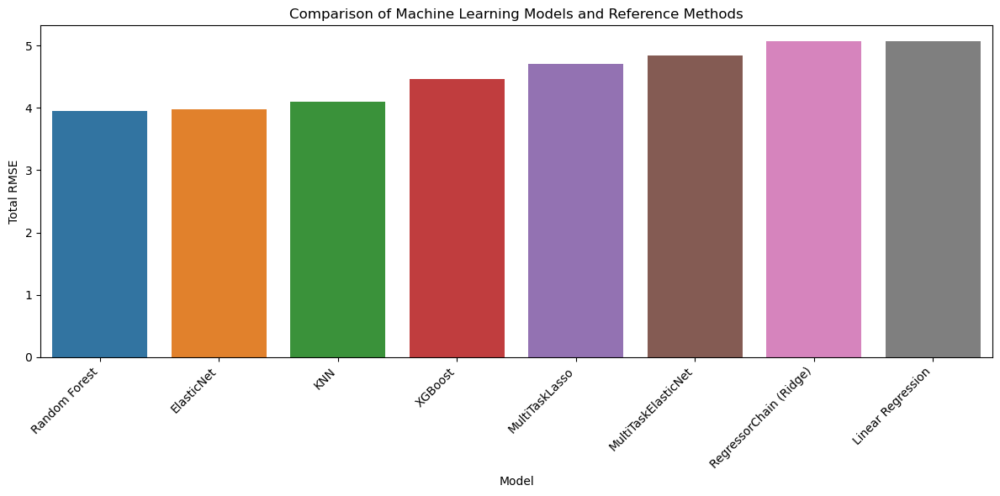

In [968]:
plt.figure(figsize=(12, 6))
sns.barplot(x='Model', y='Total RMSE', data=results_df)
plt.xticks(rotation=45, ha='right')
plt.title('Comparison of Machine Learning Models and Reference Methods')
plt.tight_layout()
plt.show()

In [969]:
best_model_name = results_df.iloc[0]['Model']
best_model = dict(all_models)[best_model_name]

# Hyperparameter tuning for the best model


In [970]:
param_grid = {}
if isinstance(best_model, ElasticNet):
    param_grid = {
        'model__estimator__alpha': [0.01, 0.1, 1.0],
        'model__estimator__l1_ratio': [0.2, 0.5, 0.8],
        'model__estimator__max_iter': [10000]
    }
elif isinstance(best_model, RandomForestRegressor):
    param_grid = {
        'model__estimator__n_estimators': [50, 100, 200],
        'model__estimator__max_depth': [None, 10, 20],
        'model__estimator__min_samples_split': [2, 5, 10]
    }
elif isinstance(best_model, Ridge):
    param_grid = {
        'model__estimator__alpha': [0.1, 1.0, 10.0]
    }

if param_grid:
    tscv = TimeSeriesSplit(n_splits=5)
    grid_search = GridSearchCV(pipeline, param_grid, cv=tscv, scoring='neg_mean_squared_error', n_jobs=-1)
    grid_search.fit(X_train_selected, y_train)
    print("Best parameters:", grid_search.best_params_)
    best_model = grid_search.best_estimator_
else:
    best_model = pipeline
    best_model.fit(X_train_selected, y_train)


Best parameters: {'model__estimator__max_depth': 10, 'model__estimator__min_samples_split': 2, 'model__estimator__n_estimators': 50}


In [971]:
# Assuming selected_features_uni contains the features used during training
X_test_aligned = X_test[selected_features_uni]
y_pred = best_model.predict(X_test_aligned)


In [972]:
final_rmse = np.sqrt(mean_squared_error(y_test, y_pred, multioutput='raw_values'))

print("\nFinal RMSE per time block:", final_rmse)

print("Total RMSE:", np.sum(final_rmse))


Final RMSE per time block: [0.28458215 0.60863567 0.27681771 0.82102794 1.26693768 0.59170539]
Total RMSE: 3.8497065454849597


# Feature Importance Analysis



Feature Importance:
                                                                                   Feature  \
16                                                              wind_wind_fc_meteo_mw_mean   
2                                      demand_National Demand Forecast (NDF) - GB (MW)_min   
8              price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_std   
3                                   demand_National Demand Forecast (NDF) - GB (MW)_spread   
9   price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_rolling_std_7d   
19                                                                                   month   
5              price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max   
1                                      demand_National Demand Forecast (NDF) - GB (MW)_max   
11              price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_cv   
6              price_Price average fore

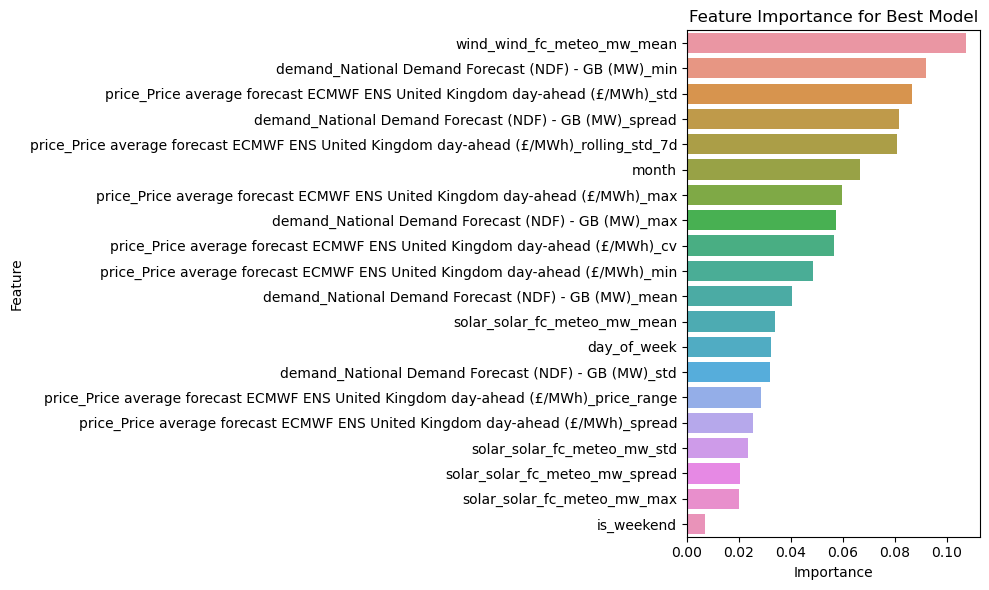

In [973]:
feature_importance = None
if hasattr(best_model, 'named_steps'):
    if hasattr(best_model.named_steps['model'], 'estimators_'):
        importances = []
        for estimator in best_model.named_steps['model'].estimators_:
            if hasattr(estimator, 'feature_importances_'):
                importances.append(estimator.feature_importances_)
        
        if importances:
            avg_importance = np.mean(importances, axis=0)
            feature_importance = pd.DataFrame({
                'Feature': selected_features_uni,
                'Importance': avg_importance
            }).sort_values('Importance', ascending=False)
    elif hasattr(best_model.named_steps['model'].estimator, 'feature_importances_'):
        importances = best_model.named_steps['model'].estimator.feature_importances_
        feature_importance = pd.DataFrame({
            'Feature': selected_features_uni,
            'Importance': importances
        }).sort_values('Importance', ascending=False)

if feature_importance is not None:
    print("\nFeature Importance:")
    print(feature_importance)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_importance)
    plt.title('Feature Importance for Best Model')
    plt.tight_layout()
    plt.savefig('../src/data/processed/feature_importance.png')
    plt.show()


In [974]:
final_results = pd.DataFrame({
    'Model': [best_model_name, 'K-means Reference', 'Euclidean Reference'],
    'Total RMSE': [np.sum(final_rmse), kmeans_total_rmse, euclidean_total_rmse]
})
final_results.to_csv('../src/data/processed/final_comparison_results.csv', index=False)
print("\nFinal Comparison Results:")
print(final_results)


Final Comparison Results:
                 Model  Total RMSE
0        Random Forest    3.849707
1    K-means Reference   85.937599
2  Euclidean Reference   92.136138


# uncertainty quantification

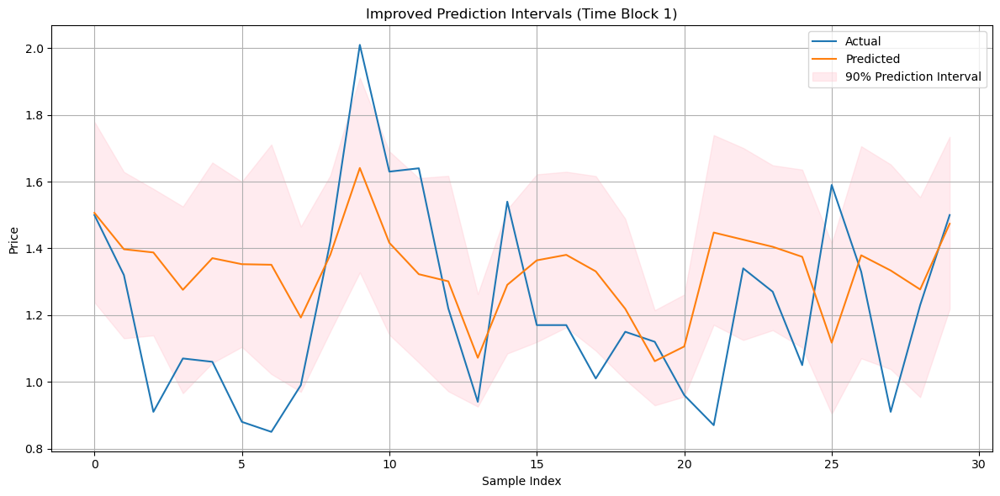

In [975]:
n_bootstraps = 500
y_mean, y_lower, y_upper = calculate_prediction_intervals(
    best_model,
    X_train_selected,
    y_train,
    X_test_selected,
    n_bootstraps=n_bootstraps,
    alpha=0.1
)

plt.figure(figsize=(12, 6))
time_block = 0 
plt.plot(y_test.values[:, time_block], label='Actual')
plt.plot(y_mean[:, time_block], label='Predicted')
plt.fill_between(
    range(len(y_test)),
    y_lower[:, time_block],
    y_upper[:, time_block],
    color='pink',
    alpha=0.3,
    label='90% Prediction Interval'
)
plt.title(f'Improved Prediction Intervals (Time Block {time_block+1})')
plt.xlabel('Sample Index')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [976]:
from sklearn.gaussian_process.kernels import Matern
from sklearn.gaussian_process.kernels import DotProduct, WhiteKernel

gp_models = []
gp_predictions = []
gp_stds = []

for i in range(y_train.shape[1]):
    kernel = Matern(length_scale=1.0, nu=1.5) + WhiteKernel(noise_level=0.1)
    gpr = GaussianProcessRegressor(kernel=kernel, alpha=0.1, n_restarts_optimizer=5, random_state=42)
    
    gpr.fit(X_train_selected, y_train.iloc[:, i])
    
    y_pred_gpr, y_std_gpr = gpr.predict(X_test_selected, return_std=True)
    
    gp_models.append(gpr)
    gp_predictions.append(y_pred_gpr)
    gp_stds.append(y_std_gpr)



In [977]:
gp_predictions = np.array(gp_predictions).T 
gp_stds = np.array(gp_stds).T 



# RMSE for Gaussian Process predictions


In [978]:
gp_rmse = np.sqrt(mean_squared_error(y_test, gp_predictions, multioutput='raw_values'))
print("\nGaussian Process RMSE per time block:", gp_rmse)
print("Total Gaussian Process RMSE:", np.sum(gp_rmse))




Gaussian Process RMSE per time block: [0.28066137 0.75413962 0.32091115 0.8142557  1.28998884 0.65316888]
Total Gaussian Process RMSE: 4.11312557204458


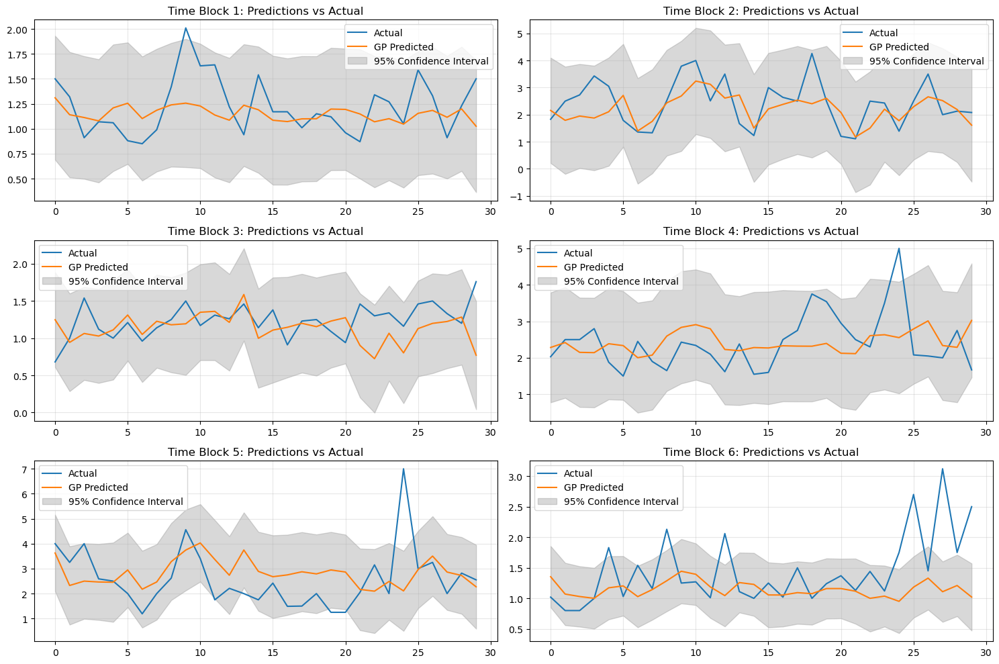

In [979]:
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(3, 2, i+1)
    plt.plot(y_test.values[:, i], label='Actual')
    plt.plot(gp_predictions[:, i], label='GP Predicted')
    
    plt.fill_between(
        range(len(y_test)),
        gp_predictions[:, i] - 1.96 * gp_stds[:, i],
        gp_predictions[:, i] + 1.96 * gp_stds[:, i],
        color='gray',
        alpha=0.3,
        label='95% Confidence Interval'
    )
    
    plt.title(f'Time Block {i+1}: Predictions vs Actual')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../src/data/processed/predictions_vs_actual.png')
plt.show()



In [980]:
print("Unique Model Labels in results_df:")
print(results_df['Model'].unique())


Unique Model Labels in results_df:
['Random Forest' 'ElasticNet' 'KNN' 'XGBoost' 'MultiTaskLasso'
 'MultiTaskElasticNet' 'RegressorChain (Ridge)' 'Linear Regression']


In [981]:
final_results = pd.DataFrame({
    'Model': [best_model_name, 'Gaussian Process', 'K-means Reference', 'Euclidean Reference'],
    'Total RMSE': [np.sum(final_rmse), np.sum(gp_rmse), kmeans_total_rmse, euclidean_total_rmse],
    'Improvement vs K-means (%)': [
        100 * (kmeans_total_rmse - np.sum(final_rmse)) / kmeans_total_rmse,
        100 * (kmeans_total_rmse - np.sum(gp_rmse)) / kmeans_total_rmse,
        0,
        -100 * (euclidean_total_rmse - kmeans_total_rmse) / kmeans_total_rmse
    ]
})

print("\nFinal Comparison Results:")
print(final_results)

final_results.to_csv('../src/data/processed/final_comparison_results.csv', index=False)




Final Comparison Results:
                 Model  Total RMSE  Improvement vs K-means (%)
0        Random Forest    3.849707                   95.520347
1     Gaussian Process    4.113126                   95.213823
2    K-means Reference   85.937599                    0.000000
3  Euclidean Reference   92.136138                   -7.212838


In [982]:
interval_data = pd.DataFrame() 
for i in range(6):
    block_data = pd.DataFrame({
        'actual': y_test.iloc[:, i].values,
        'predicted': gp_predictions[:, i],
        'lower_bound': gp_predictions[:, i] - 1.96 * gp_stds[:, i],
        'upper_bound': gp_predictions[:, i] + 1.96 * gp_stds[:, i],
        'time_block': i + 1
    })
    interval_data = pd.concat([interval_data, block_data])

interval_data.to_csv('../src/data/processed/prediction_intervals.csv', index=False)
print("Prediction intervals saved!")

Prediction intervals saved!


### prediction intervals using individual trees in the random forest

In [983]:
def rf_prediction_intervals(model, X_test, percentile=95):
        predictions = np.array([tree.predict(X_test) for tree in model.estimators_])
    
        y_mean = np.mean(predictions, axis=0)
    
        lower_percentile = (100 - percentile) / 2
        upper_percentile = 100 - lower_percentile
    
        y_lower = np.percentile(predictions, lower_percentile, axis=0)
        y_upper = np.percentile(predictions, upper_percentile, axis=0)
    
        return y_mean, y_lower, y_upper


### prediction intervals using bootstrap sampling

In [984]:
def rf_bootstrap_intervals(model, X_train, y_train, X_test, n_bootstraps=500, alpha=0.1):
 
    predictions = np.zeros((n_bootstraps, X_test.shape[0], y_train.shape[1]))
    
    for i in range(n_bootstraps):
     
        indices = np.random.choice(len(X_train), len(X_train), replace=True)
        X_boot, y_boot = X_train.iloc[indices], y_train.iloc[indices]
        
        boot_model = clone(model)
        boot_model.fit(X_boot, y_boot)
        
        predictions[i] = boot_model.predict(X_test)
    
    y_mean = np.mean(predictions, axis=0)
    y_lower = np.percentile(predictions, alpha/2 * 100, axis=0)
    y_upper = np.percentile(predictions, (1 - alpha/2) * 100, axis=0)
    
    return y_mean, y_lower, y_upper


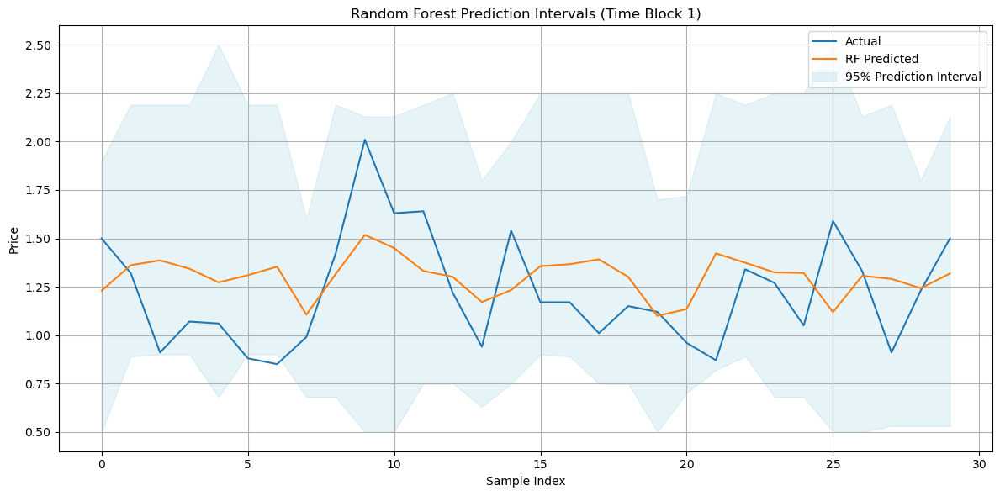

In [985]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import clone
import numpy as np
import matplotlib.pyplot as plt

rf_model = RandomForestRegressor(n_estimators=10000, random_state=40)
rf_model.fit(X_train_selected, y_train)

y_mean, y_lower, y_upper = rf_prediction_intervals(
    rf_model, 
    X_test_selected, 
    percentile=90
)

plt.figure(figsize=(12, 6))
time_block = 0  
plt.plot(y_test.values[:, time_block], label='Actual')
plt.plot(y_mean[:, time_block], label='RF Predicted')
plt.fill_between(
    range(len(y_test)),
    y_lower[:, time_block],
    y_upper[:, time_block],
    color='lightblue',
    alpha=0.3,
    label='95% Prediction Interval'
)
plt.title(f'Random Forest Prediction Intervals (Time Block {time_block+1})')
plt.xlabel('Sample Index')
plt.ylabel('Price')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


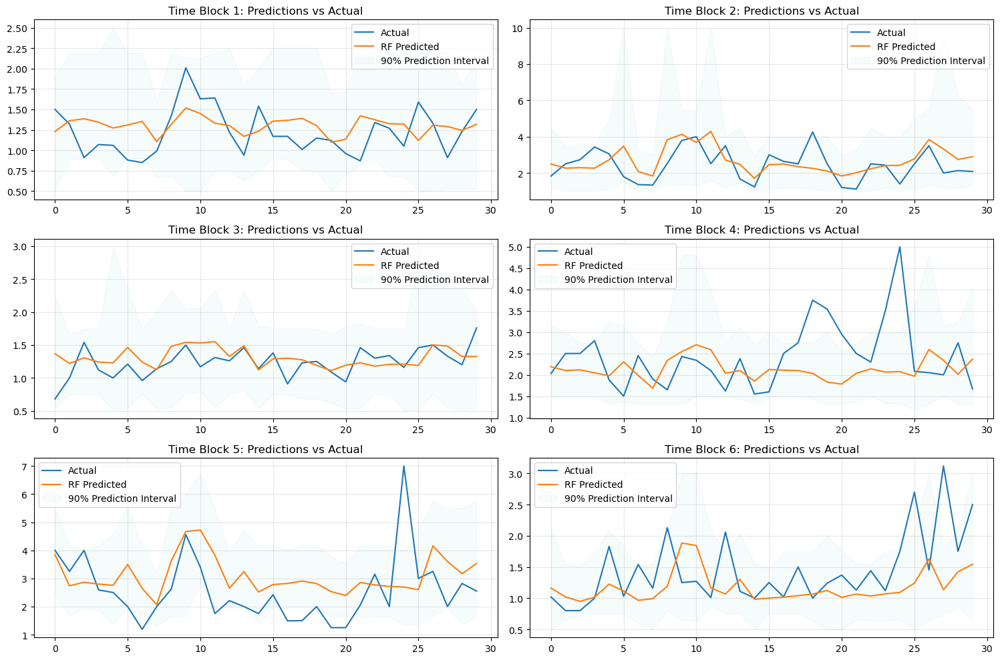

In [986]:
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(3, 2, i+1)
    plt.plot(y_test.values[:, i], label='Actual')
    plt.plot(y_mean[:, i], label='RF Predicted')
    
    plt.fill_between(
        range(len(y_test)),
        y_lower[:, i],
        y_upper[:, i],
        color='lightblue',
        alpha=0.1,
        label='90% Prediction Interval'
    )
    
    plt.title(f'Time Block {i+1}: Predictions vs Actual')
    plt.legend()
    plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../src/data/processed/rf_predictions_vs_actual.png')
plt.show()


In [987]:
global_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print("Global RMSE:", global_rmse)


Global RMSE: 0.7254177723897425


### took reference metrics with whole year to compare, calculate here RMSE


In [988]:
import pandas as pd
import numpy as np
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error

daily_metrics = pd.read_csv('../src/data/processed/daily_metrics.csv', parse_dates=['date'])

dcl_prices = pd.read_csv('../src/data/processed/gb_dcl_prices_gbp_per_mw_per_hour.csv', parse_dates=['dtutc'])
dcl_prices['date'] = dcl_prices['dtutc'].dt.date
dcl_prices['time_block'] = dcl_prices['dtutc'].dt.hour // 4 + 1

pivot_prices = dcl_prices.pivot_table(index='date', columns='time_block', values='dcl_price', aggfunc='first')
pivot_prices.columns = [f'block_{i}' for i in range(1, 7)]
pivot_prices = pivot_prices.reset_index()
pivot_prices['date'] = pd.to_datetime(pivot_prices['date'])


In [989]:
train_end_date = pd.Timestamp('2024-07-31')
test_start_date = pd.Timestamp('2024-08-01')
test_end_date = pd.Timestamp('2024-12-31')

feature_cols = [
    'demand_National Demand Forecast (NDF) - GB (MW)_mean',
    'demand_National Demand Forecast (NDF) - GB (MW)_max',
    'demand_National Demand Forecast (NDF) - GB (MW)_min',
    'demand_National Demand Forecast (NDF) - GB (MW)_spread',
    'demand_National Demand Forecast (NDF) - GB (MW)_std',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_std',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_rolling_std_7d',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_price_range',
    'price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_cv',
    'solar_solar_fc_meteo_mw_mean', 
    'solar_solar_fc_meteo_mw_max',
    'solar_solar_fc_meteo_mw_min', 
    'solar_solar_fc_meteo_mw_spread',
    'solar_solar_fc_meteo_mw_std', 
    'wind_wind_fc_meteo_mw_mean',
    'wind_wind_fc_meteo_mw_max', 
    'wind_wind_fc_meteo_mw_min',
    'wind_wind_fc_meteo_mw_spread', 
    'wind_wind_fc_meteo_mw_std',
    'day_of_week', 
    'is_weekend', 
    'month'
]


In [990]:
clustering_data = daily_metrics[feature_cols].copy()

clustering_data = clustering_data.fillna(clustering_data.mean())

scaler = StandardScaler()
scaled_data = scaler.fit_transform(clustering_data)


n_clusters = 12
kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
daily_metrics['cluster'] = kmeans.fit_predict(scaled_data)


In [991]:
def find_reference_day(test_day, historical_data):

    test_cluster = test_day['cluster']
    
    
    cluster_days = historical_data[historical_data['cluster'] == test_cluster]
    
    if cluster_days.empty:
        cluster_days = historical_data
    
    distances = []
    for _, hist_day in cluster_days.iterrows():
        month_diff = abs(test_day['month'] - hist_day['month'])
        dow_diff = abs(test_day['day_of_week'] - hist_day['day_of_week'])
        is_weekend_diff = abs(test_day['is_weekend'] - hist_day['is_weekend'])
        
        distance = month_diff + dow_diff + is_weekend_diff*3 
        distances.append((hist_day['date'], distance))
    
    distances.sort(key=lambda x: x[1])
    return distances[0][0] if distances else None

historical_data = daily_metrics[daily_metrics['date'] <= train_end_date].copy()
test_data = daily_metrics[(daily_metrics['date'] >= test_start_date) & 
                         (daily_metrics['date'] <= test_end_date)].copy()

reference_mapping = []
for _, test_day in test_data.iterrows():
    ref_date = find_reference_day(test_day, historical_data)
    if ref_date is not None:
        reference_mapping.append({
            'delivery_date': test_day['date'],
            'reference_date': ref_date
        })

kmeans_mapping = pd.DataFrame(reference_mapping)


In [928]:
kmeans_mapping['delivery_date'] = pd.to_datetime(kmeans_mapping['delivery_date'])
kmeans_mapping['reference_date'] = pd.to_datetime(kmeans_mapping['reference_date'])

df = kmeans_mapping.merge(pivot_prices, left_on='delivery_date', right_on='date', how='left', suffixes=('', '_actual'))
df = df.merge(pivot_prices, left_on='reference_date', right_on='date', how='left', suffixes=('', '_ref'))

rmses = []
for i in range(1, 7):
    actual = df[f'block_{i}']
    ref = df[f'block_{i}_ref']
    mask = (~actual.isna()) & (~ref.isna())
    rmse = np.sqrt(mean_squared_error(actual[mask], ref[mask]))
    rmses.append(rmse)
    print(f"RMSE for Block {i}: {rmse:.4f}")

# Total RMSE (sum of block RMSEs)
total_rmse = np.sum(rmses)
print(f"\nTotal RMSE with 12 months of data: {total_rmse:.4f}")


RMSE for Block 1: 1.4658
RMSE for Block 2: 1.9429
RMSE for Block 3: 1.2066
RMSE for Block 4: 9.3760
RMSE for Block 5: 2.1226
RMSE for Block 6: 1.4796

Total RMSE with 12 months of data: 17.5935


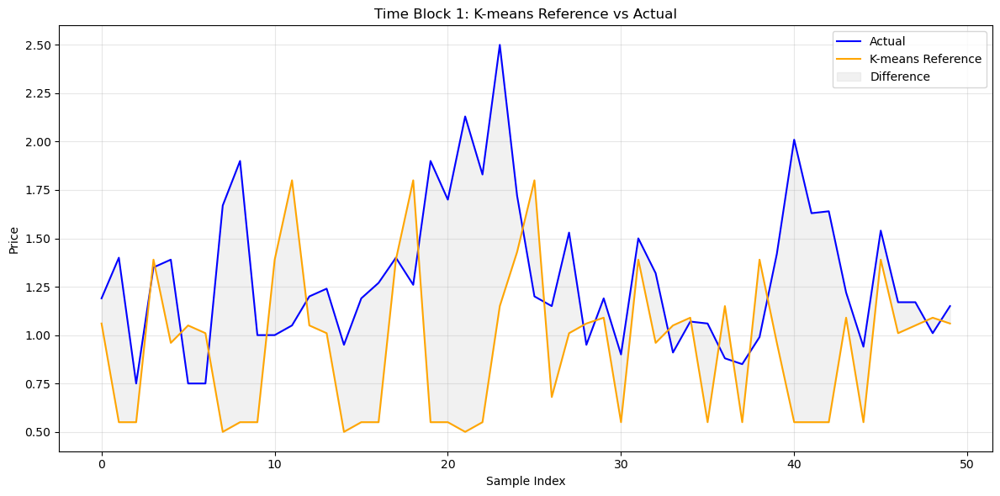

In [857]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
sample_days = 50  

sample_df = df.head(sample_days)

plt.plot(range(sample_days), sample_df['block_1'], label='Actual', color='blue')
plt.plot(range(sample_days), sample_df['block_1_ref'], label='K-means Reference', color='orange')
plt.fill_between(
    range(sample_days),
    sample_df['block_1'],
    sample_df['block_1_ref'],
    color='lightgray',
    alpha=0.3,
    label='Difference'
)
plt.title('Time Block 1: K-means Reference vs Actual')
plt.xlabel('Sample Index')
plt.ylabel('Price')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('kmeans_vs_actual_comparison.png')
plt.show()


# Reference day comparisons 

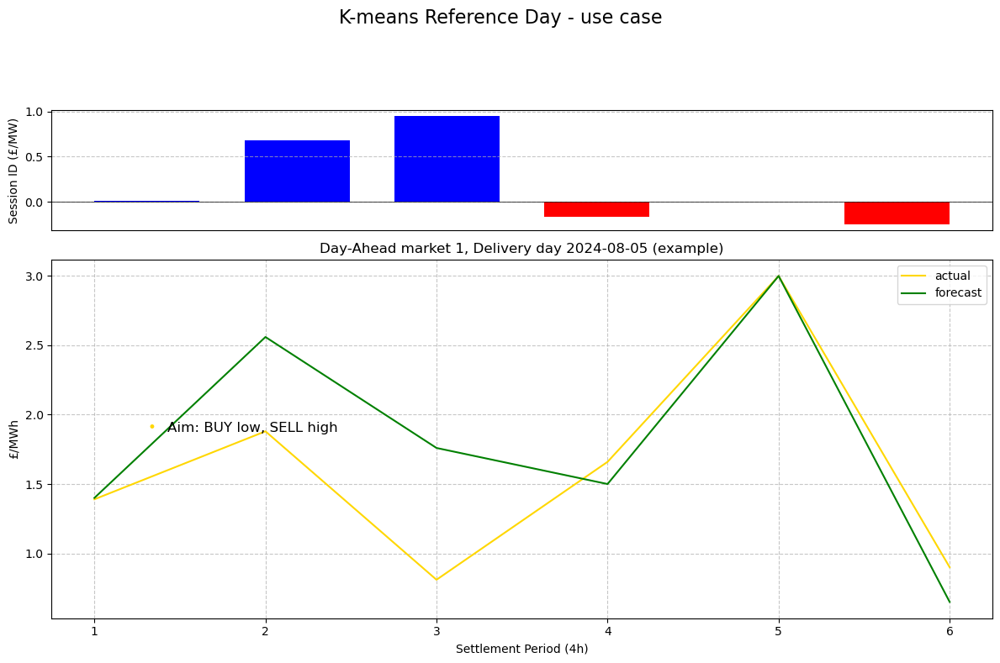

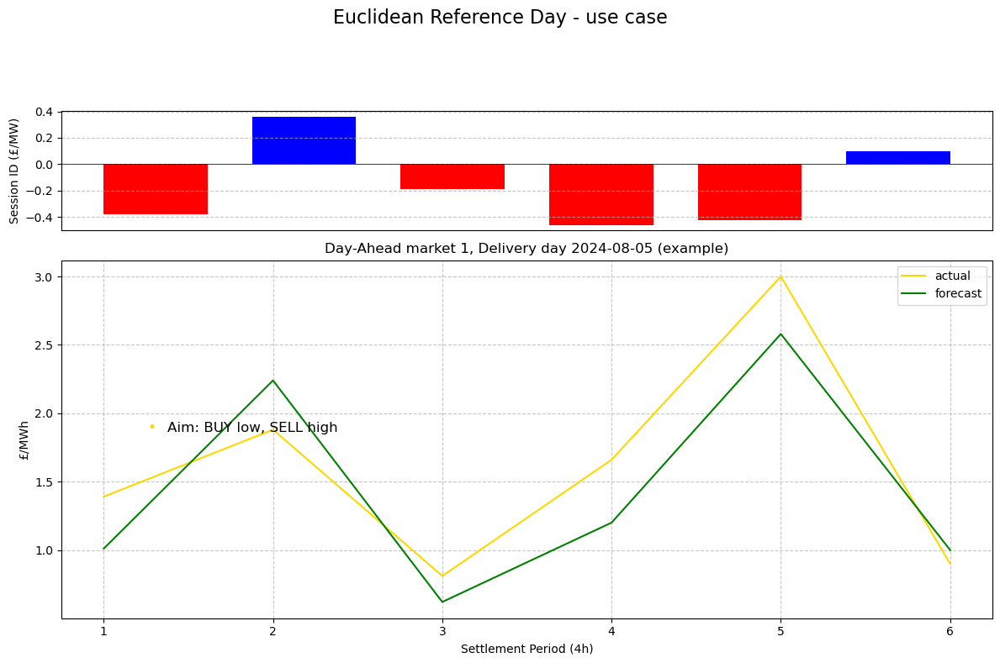

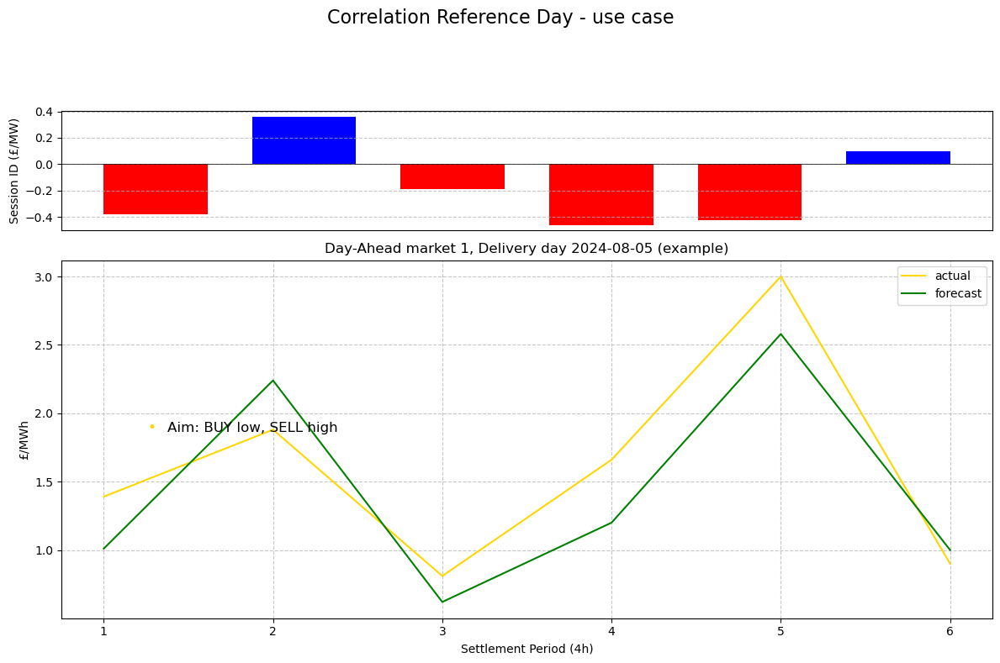

In [858]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
import re

dcl_prices = pd.read_csv('../src/data/processed/gb_dcl_prices_gbp_per_mw_per_hour.csv', parse_dates=['dtutc'])
dcl_prices['date'] = dcl_prices['dtutc'].dt.date
dcl_prices['time_block'] = dcl_prices['dtutc'].dt.hour // 4 + 1  # 4-hour blocks (1-6)

kmeans_refs = pd.read_csv('../src/data/processed/kmeans_reference_mapping_approach2.csv', parse_dates=['delivery_date', 'reference_date'])

def extract_reference_date(ref_str):
    if pd.isna(ref_str): return None
    match = re.search(r"(\d{4}-\d{2}-\d{2})", str(ref_str))
    return pd.to_datetime(match.group(1)) if match else None

euclidean_refs = pd.read_csv('../src/data/processed/reference_days_euclidean_table.csv')
euclidean_refs['delivery_date'] = pd.to_datetime(euclidean_refs['date'])
euclidean_refs['reference_date'] = euclidean_refs['closest_reference_days'].apply(extract_reference_date)

correlation_refs = pd.read_csv('../src/data/processed/reference_days_correlation_table.csv')
correlation_refs['delivery_date'] = pd.to_datetime(correlation_refs['date'])
correlation_refs['reference_date'] = correlation_refs['closest_reference_days'].apply(extract_reference_date)

def create_reference_day_plot(delivery_date, reference_date, method_name):
    delivery_prices = dcl_prices[dcl_prices['date'] == delivery_date].sort_values('time_block')
    reference_prices = dcl_prices[dcl_prices['date'] == reference_date].sort_values('time_block')
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), gridspec_kw={'height_ratios': [1, 3]})
    
    settlement_periods = delivery_prices['time_block'].values
    
    differences = reference_prices['dcl_price'].values - delivery_prices['dcl_price'].values
    
    ax1.bar(settlement_periods, differences, color=['blue' if d > 0 else 'red' for d in differences], width=0.7)
    ax1.axhline(y=0, color='black', linestyle='-', linewidth=0.5)
    ax1.set_ylabel('Session ID (£/MW)')
    ax1.grid(True, linestyle='--', alpha=0.7)
    ax1.set_xticks([])
    
    ax2.plot(settlement_periods, delivery_prices['dcl_price'].values, label='actual', color='gold')
    ax2.plot(settlement_periods, reference_prices['dcl_price'].values, label='forecast', color='green')
    ax2.set_xlabel('Settlement Period (4h)')
    ax2.set_ylabel('£/MWh')
    ax2.grid(True, linestyle='--', alpha=0.7)
    ax2.legend()
    
    plt.suptitle(f'{method_name} Reference Day - use case', fontsize=16)
    plt.title(f'Day-Ahead market 1, Delivery day {delivery_date} (example)', fontsize=12)
    
    y_pos = 0.35
    for note in ["Aim: BUY low, SELL high"]:
        plt.figtext(0.15, y_pos, "•", fontsize=12, color='gold')
        plt.figtext(0.17, y_pos, note, fontsize=12)
        y_pos -= 0.03
    
    plt.tight_layout(rect=[0, 0, 1, 0.9])
    return fig

sample_date = datetime(2024, 8, 5).date()

k_ref_date = kmeans_refs[kmeans_refs['delivery_date'].dt.date == sample_date]['reference_date'].iloc[0].date()
e_ref_date = euclidean_refs[euclidean_refs['delivery_date'].dt.date == sample_date]['reference_date'].iloc[0].date()
c_ref_date = correlation_refs[correlation_refs['delivery_date'].dt.date == sample_date]['reference_date'].iloc[0].date()

kmeans_plot = create_reference_day_plot(sample_date, k_ref_date, "K-means")
kmeans_plot.savefig('kmeans_reference_day_plot.png', dpi=300)

euclidean_plot = create_reference_day_plot(sample_date, e_ref_date, "Euclidean")
euclidean_plot.savefig('euclidean_reference_day_plot.png', dpi=300)

correlation_plot = create_reference_day_plot(sample_date, c_ref_date, "Correlation")
correlation_plot.savefig('correlation_reference_day_plot.png', dpi=300)

plt.show()


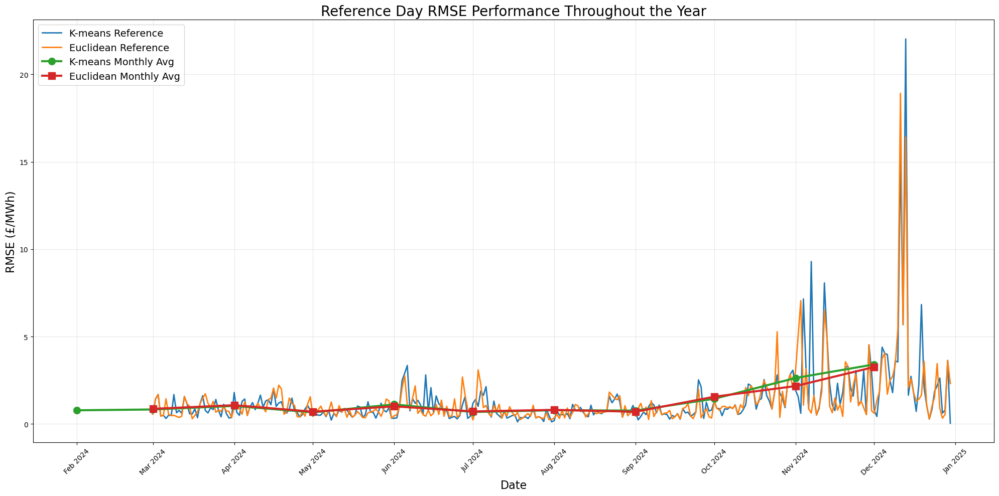

In [859]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from datetime import datetime
import re

dcl_prices = pd.read_csv('../src/data/processed/gb_dcl_prices_gbp_per_mw_per_hour.csv', parse_dates=['dtutc'])
dcl_prices['date'] = dcl_prices['dtutc'].dt.date
dcl_prices['time_block'] = dcl_prices['dtutc'].dt.hour // 4 + 1

kmeans_refs = pd.read_csv('../src/data/processed/kmeans_reference_mapping_approach2.csv', parse_dates=['delivery_date', 'reference_date'])

def extract_reference_date(ref_str):
    if pd.isna(ref_str): return None
    match = re.search(r"(\d{4}-\d{2}-\d{2})", str(ref_str))
    return pd.to_datetime(match.group(1)) if match else None

euclidean_refs = pd.read_csv('../src/data/processed/reference_days_euclidean_table.csv')
euclidean_refs['delivery_date'] = pd.to_datetime(euclidean_refs['date'])
euclidean_refs['reference_date'] = euclidean_refs['closest_reference_days'].apply(extract_reference_date)

def calculate_daily_rmse(delivery_date, reference_date):
    delivery_prices = dcl_prices[dcl_prices['date'] == delivery_date.date()].sort_values('time_block')
    reference_prices = dcl_prices[dcl_prices['date'] == reference_date.date()].sort_values('time_block')
    
    if len(delivery_prices) == 0 or len(reference_prices) == 0:
        return None
    
    min_length = min(len(delivery_prices), len(reference_prices))
    rmse = np.sqrt(np.mean((delivery_prices['dcl_price'].values[:min_length] - 
                            reference_prices['dcl_price'].values[:min_length])**2))
    return rmse

kmeans_results = []
for _, row in kmeans_refs.iterrows():
    rmse = calculate_daily_rmse(row['delivery_date'], row['reference_date'])
    if rmse is not None:
        kmeans_results.append({
            'delivery_date': row['delivery_date'],
            'rmse': rmse
        })

euclidean_results = []
for _, row in euclidean_refs.iterrows():
    if pd.notna(row['reference_date']):
        rmse = calculate_daily_rmse(row['delivery_date'], row['reference_date'])
        if rmse is not None:
            euclidean_results.append({
                'delivery_date': row['delivery_date'],
                'rmse': rmse
            })

kmeans_df = pd.DataFrame(kmeans_results)
euclidean_df = pd.DataFrame(euclidean_results)

plt.figure(figsize=(20, 10))
plt.plot(kmeans_df['delivery_date'], kmeans_df['rmse'], label='K-means Reference', linewidth=2)
plt.plot(euclidean_df['delivery_date'], euclidean_df['rmse'], label='Euclidean Reference', linewidth=2)

kmeans_df['month'] = kmeans_df['delivery_date'].dt.to_period('M')
euclidean_df['month'] = euclidean_df['delivery_date'].dt.to_period('M')

kmeans_monthly = kmeans_df.groupby('month')['rmse'].mean()
euclidean_monthly = euclidean_df.groupby('month')['rmse'].mean()

months = pd.date_range(start='2024-01-01', end='2024-12-31', freq='MS')
plt.plot(months, [kmeans_monthly.get(pd.Period(m, 'M'), np.nan) for m in months], 
         'o-', markersize=10, linewidth=3, label='K-means Monthly Avg')
plt.plot(months, [euclidean_monthly.get(pd.Period(m, 'M'), np.nan) for m in months], 
         's-', markersize=10, linewidth=3, label='Euclidean Monthly Avg')

plt.title('Reference Day RMSE Performance Throughout the Year', fontsize=20)
plt.xlabel('Date', fontsize=16)
plt.ylabel('RMSE (£/MWh)', fontsize=16)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=14)

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.gca().xaxis.set_major_locator(mdates.MonthLocator())
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig('yearly_reference_performance.png', dpi=300)
plt.show()


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


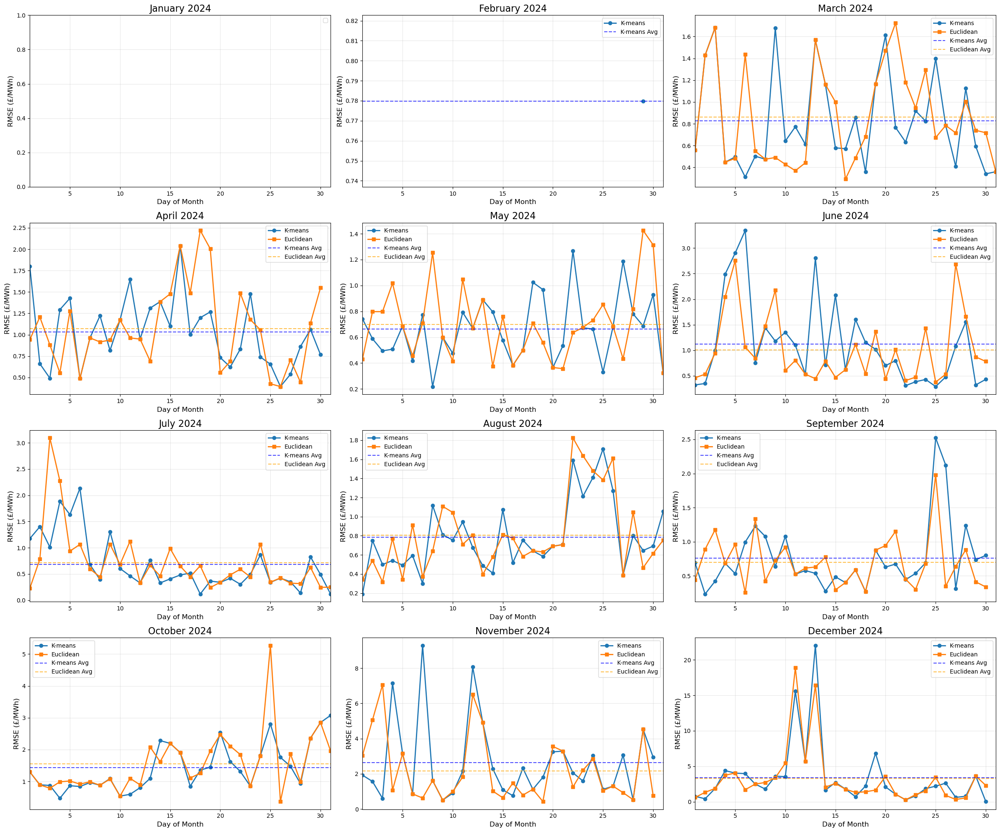

In [860]:
def create_monthly_comparison_plot(year=2024):
    fig, axes = plt.subplots(4, 3, figsize=(24, 20))
    axes = axes.flatten()
    
    for month_idx, month in enumerate(range(1, 13)):
        ax = axes[month_idx]
        
        month_start = pd.Timestamp(f'{year}-{month:02d}-01')
        if month == 12:
            month_end = pd.Timestamp(f'{year+1}-01-01') - pd.Timedelta(days=1)
        else:
            month_end = pd.Timestamp(f'{year}-{month+1:02d}-01') - pd.Timedelta(days=1)
        
        kmeans_month = kmeans_df[(kmeans_df['delivery_date'] >= month_start) & 
                                 (kmeans_df['delivery_date'] <= month_end)]
        euclidean_month = euclidean_df[(euclidean_df['delivery_date'] >= month_start) & 
                                      (euclidean_df['delivery_date'] <= month_end)]
        
        
        if not kmeans_month.empty:
            ax.plot(kmeans_month['delivery_date'].dt.day, kmeans_month['rmse'], 
                   'o-', label='K-means', linewidth=2)
        if not euclidean_month.empty:
            ax.plot(euclidean_month['delivery_date'].dt.day, euclidean_month['rmse'], 
                   's-', label='Euclidean', linewidth=2)
        
        if not kmeans_month.empty:
            ax.axhline(y=kmeans_month['rmse'].mean(), color='blue', linestyle='--', 
                      alpha=0.7, label='K-means Avg')
        if not euclidean_month.empty:
            ax.axhline(y=euclidean_month['rmse'].mean(), color='orange', linestyle='--', 
                      alpha=0.7, label='Euclidean Avg')
        
        month_name = month_start.strftime('%B %Y')
        ax.set_title(f'{month_name}', fontsize=16)
        ax.set_xlabel('Day of Month', fontsize=12)
        ax.set_ylabel('RMSE (£/MWh)', fontsize=12)
        ax.grid(True, alpha=0.3)
        ax.legend()
        
        ax.set_xlim(1, 31)  
    
    plt.tight_layout()
    plt.savefig('monthly_reference_performance.png', dpi=300)
    plt.show()

create_monthly_comparison_plot(2024)


findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.


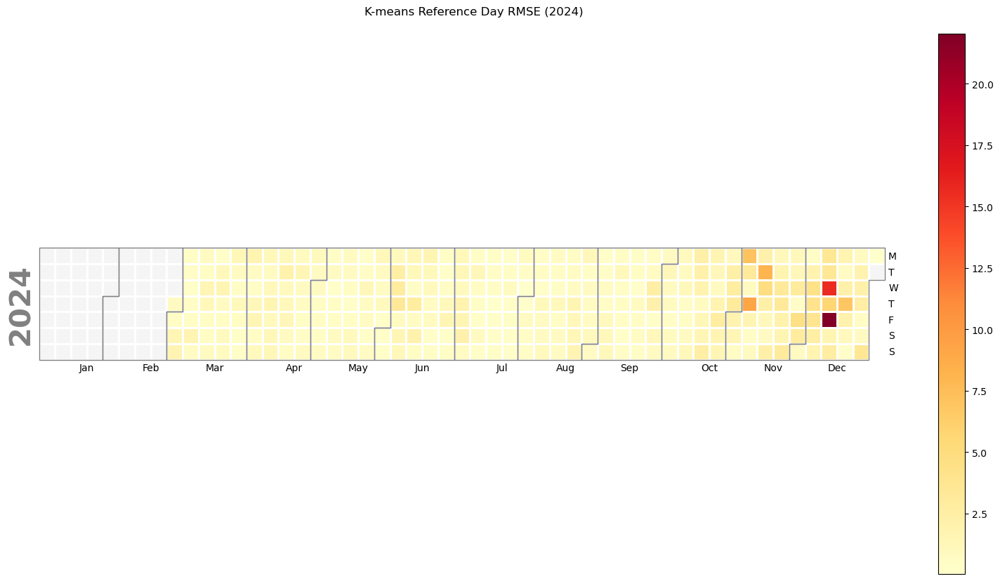

findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.
findfont: Font family 'Helvetica' not found.


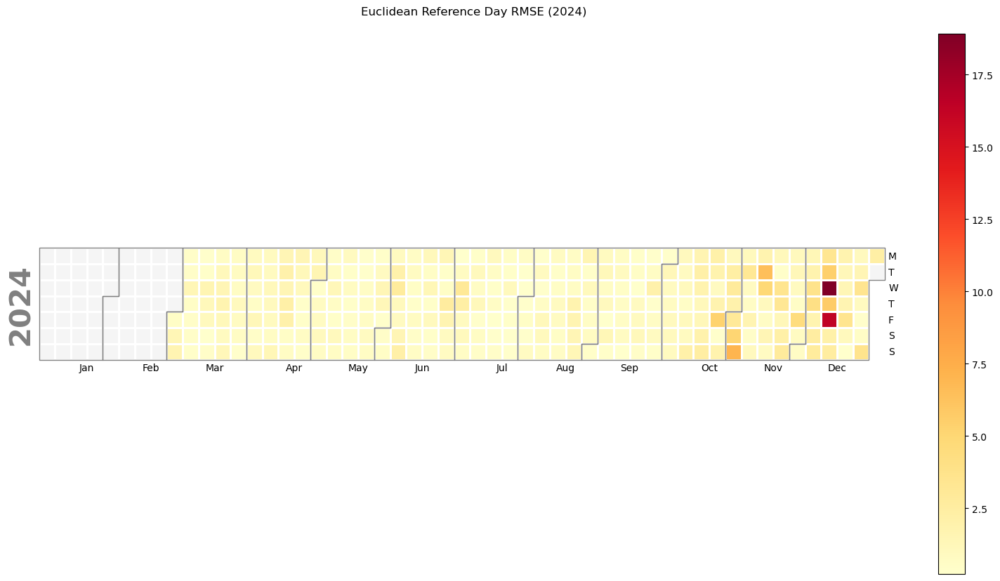

In [861]:
import calplot
import matplotlib.pyplot as plt

kmeans_calendar = kmeans_df.set_index('delivery_date')['rmse']
euclidean_calendar = euclidean_df.set_index('delivery_date')['rmse']

fig, ax = calplot.calplot(kmeans_calendar, 
                          cmap='YlOrRd', 
                          figsize=(16, 8),
                          suptitle='K-means Reference Day RMSE (2024)',
                          daylabels='MTWTFSS',
                          fillcolor='whitesmoke')
plt.savefig('kmeans_calendar_heatmap.png', dpi=300)

fig, ax = calplot.calplot(euclidean_calendar, 
                          cmap='YlOrRd', 
                          figsize=(16, 8),
                          suptitle='Euclidean Reference Day RMSE (2024)',
                          daylabels='MTWTFSS',
                          fillcolor='whitesmoke')
plt.savefig('euclidean_calendar_heatmap.png', dpi=300)


In [ ]:
# pip install calplot


## Error Metrics Time Series Plots (RMSE & MAE)


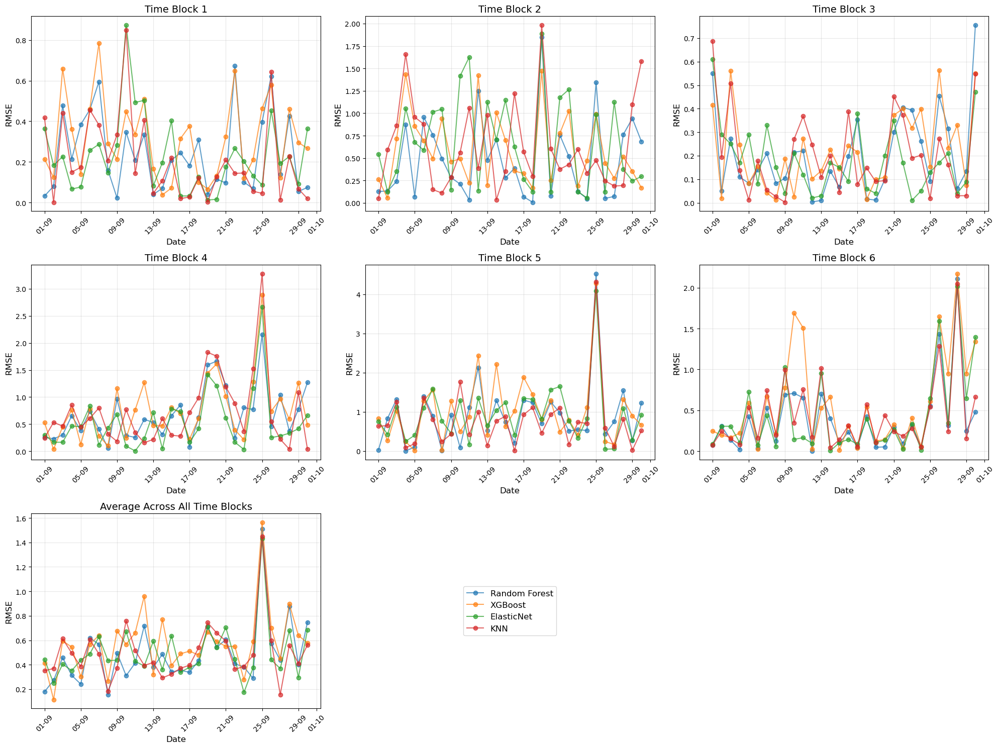

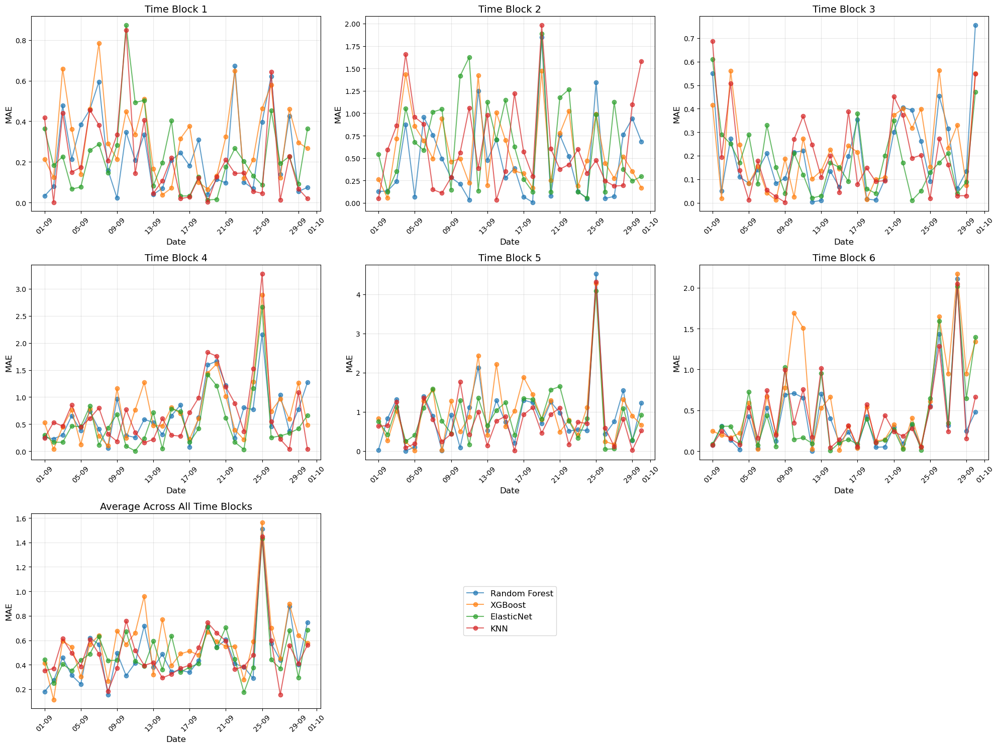

In [1039]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error
import matplotlib.dates as mdates

def plot_error_metrics(metric_type='RMSE'):
    fig, axs = plt.subplots(3, 3, figsize=(20, 15))
    axs = axs.flatten()
    
    models_to_plot = [('Random Forest', RandomForestRegressor(random_state=42)),
                      ('XGBoost', XGBRegressor(random_state=42)),
                      ('ElasticNet', ElasticNet()),
                      ('KNN', KNeighborsRegressor())]
    
    if hasattr(y_test, 'index') and isinstance(y_test.index, pd.DatetimeIndex):
        test_dates = y_test.index
    else:
        test_dates = data.loc[y_test.index, 'date'].values if 'date' in data.columns else pd.date_range(test_start_date, periods=len(y_test))
    
    all_errors = {}
    avg_errors = {}
    
    for name, model in models_to_plot:
        if not isinstance(model, (MultiTaskLasso, MultiTaskElasticNet, RegressorChain)):
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('model', MultiOutputRegressor(model))
            ])
        else:
            pipeline = model
            
        pipeline.fit(X_train_selected, y_train)
        y_pred = pipeline.predict(X_test_selected)
        
        daily_errors = []
        for i in range(len(target_cols)):
            if metric_type == 'RMSE':
                errors = np.sqrt((y_test.iloc[:, i] - y_pred[:, i])**2)
            else: 
                metric_type == 'MAE'
                errors = np.abs(y_test.iloc[:, i] - y_pred[:, i])
            daily_errors.append(errors)
            
        all_errors[name] = daily_errors
        avg_errors[name] = np.mean(daily_errors, axis=0)
    
    for i in range(6):
        ax = axs[i]
        for name in all_errors.keys():
            ax.plot(test_dates, all_errors[name][i], label=name, marker='o', alpha=0.7)
        
        ax.set_title(f'Time Block {i+1}', fontsize=14)
        ax.set_xlabel('Date', fontsize=12)
        ax.set_ylabel(f'{metric_type}', fontsize=12)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True, alpha=0.3)
    
    
    for name in avg_errors.keys():
        axs[6].plot(test_dates, avg_errors[name], label=name, marker='o', alpha=0.7)
    
    axs[6].set_title('Average Across All Time Blocks', fontsize=14)
    axs[6].set_xlabel('Date', fontsize=12)
    axs[6].set_ylabel(f'{metric_type}', fontsize=12)
    axs[6].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    axs[6].tick_params(axis='x', rotation=45)
    axs[6].grid(True, alpha=0.3)
    
    handles, labels = axs[6].get_legend_handles_labels()
    axs[7].legend(handles, labels, loc='center', fontsize=12)
    axs[7].axis('off')
    
    axs[8].axis('off')
    
    plt.tight_layout()
    plt.savefig(f'../src/data/processed/plots/{metric_type}_time_series.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_error_metrics('RMSE')

plot_error_metrics('MAE')


In [1071]:
def plot_rmse_metrics():
    plt.close('all')
    fig, axs = plt.subplots(3, 3, figsize=(20, 15), sharey=True)
    axs = axs.flatten()
    models_to_plot = [('Random Forest', RandomForestRegressor(random_state=42)),
                      ('XGBoost', XGBRegressor(random_state=42)),
                      ('ElasticNet', ElasticNet()),
                      ('KNN', KNeighborsRegressor())]
    test_dates = pd.date_range(test_start_date, periods=len(y_test))
    all_errors = {}
    avg_errors = {}

    for name, model in models_to_plot:
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', MultiOutputRegressor(clone(model)))
        ])
        pipeline.fit(X_train_selected, y_train)
        y_pred = pipeline.predict(X_test_selected)
        daily_errors = []
        for i in range(len(y_test.columns)):
            # Correct RMSE: squared error per day for this block, then sqrt
            errors = np.sqrt((y_test.iloc[:, i] - y_pred[:, i])**2)  # This is still abs error!
            daily_errors.append(errors)
        # The correct RMSE per block per day is just abs error, so instead:
        # Instead, for each block, do NOT take sqrt of squared error, but take mean of squared errors per block, THEN sqrt
        all_errors[name] = daily_errors
        # For average RMSE across all blocks per day:
        avg_errors[name] = np.sqrt(np.mean((y_test.values - y_pred) ** 2, axis=1))

    for i in range(6):
        ax = axs[i]
        for name in all_errors.keys():
            min_len = min(len(test_dates), len(all_errors[name][i]))
            ax.plot(test_dates[:min_len], all_errors[name][i][:min_len], label=name, marker='o', alpha=0.7)
        ax.set_title(f'Time Block {i+1} - RMSE', fontsize=14)
        ax.set_xlabel('Date', fontsize=12)
        ax.set_ylabel('RMSE', fontsize=12)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True, alpha=0.3)
    for name in avg_errors.keys():
        min_len = min(len(test_dates), len(avg_errors[name]))
        axs[6].plot(test_dates[:min_len], avg_errors[name][:min_len], label=name, marker='o', alpha=0.7)
    axs[6].set_title('Average Across All Time Blocks - RMSE', fontsize=14)
    axs[6].set_xlabel('Date', fontsize=12)
    axs[6].set_ylabel('RMSE', fontsize=12)
    axs[6].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    axs[6].tick_params(axis='x', rotation=45)
    axs[6].grid(True, alpha=0.3)
    axs[7].axis('off')
    axs[8].axis('off')
    handles, labels = axs[6].get_legend_handles_labels()
    axs[6].legend(handles, labels, loc='upper right', fontsize=12)
    plt.tight_layout()
    plt.savefig('../src/data/processed/plots/RMSE_time_series.png', dpi=300, bbox_inches='tight')
    plt.show()

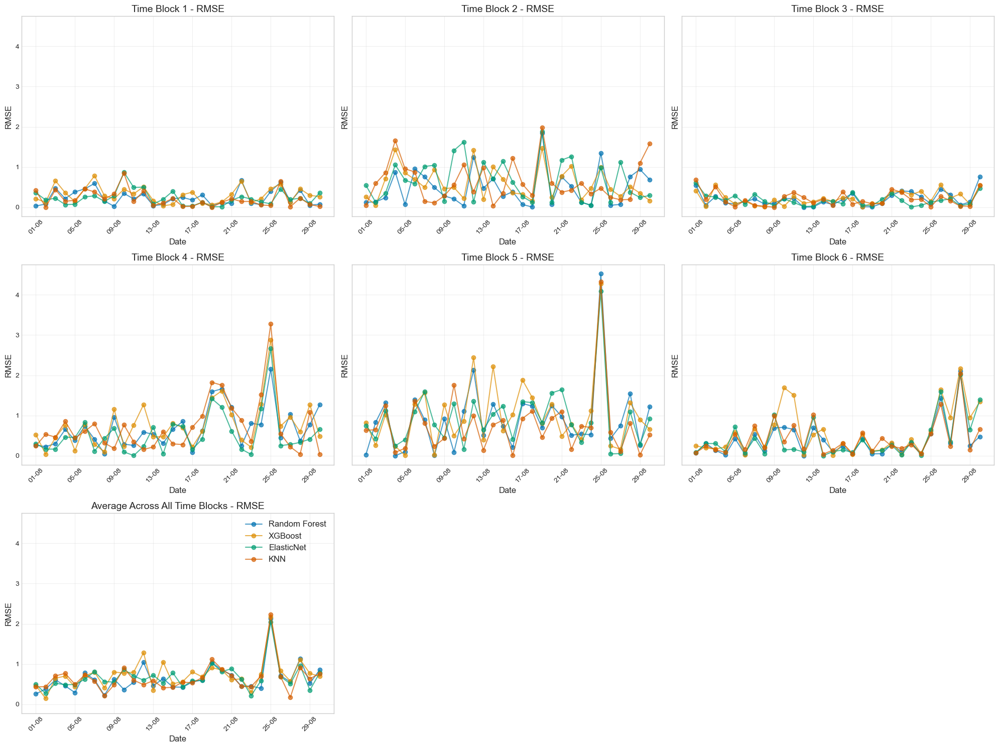

In [1072]:
plot_rmse_metrics()


In [1069]:
def plot_mae_metrics():
    plt.close('all')
    fig, axs = plt.subplots(3, 3, figsize=(20, 15), sharey=True)
    axs = axs.flatten()
    models_to_plot = [('Random Forest', RandomForestRegressor(random_state=42)),
                      ('XGBoost', XGBRegressor(random_state=42)),
                      ('ElasticNet', ElasticNet()),
                      ('KNN', KNeighborsRegressor())]
    test_dates = pd.date_range(test_start_date, periods=len(y_test))
    all_errors = {}
    avg_errors = {}

    for name, model in models_to_plot:
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', MultiOutputRegressor(clone(model)))
        ])
        pipeline.fit(X_train_selected, y_train)
        y_pred = pipeline.predict(X_test_selected)
        daily_errors = []
        for i in range(len(y_test.columns)):
            errors = np.abs(y_test.iloc[:, i] - y_pred[:, i])
            daily_errors.append(errors)
        all_errors[name] = daily_errors
        avg_errors[name] = np.mean(np.abs(y_test.values - y_pred), axis=1)

    for i in range(6):
        ax = axs[i]
        for name in all_errors.keys():
            min_len = min(len(test_dates), len(all_errors[name][i]))
            ax.plot(test_dates[:min_len], all_errors[name][i][:min_len], label=name, marker='o', alpha=0.7)
        ax.set_title(f'Time Block {i+1} - MAE', fontsize=14)
        ax.set_xlabel('Date', fontsize=12)
        ax.set_ylabel('MAE', fontsize=12)
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
        ax.tick_params(axis='x', rotation=45)
        ax.grid(True, alpha=0.3)
    for name in avg_errors.keys():
        min_len = min(len(test_dates), len(avg_errors[name]))
        axs[6].plot(test_dates[:min_len], avg_errors[name][:min_len], label=name, marker='o', alpha=0.7)
    axs[6].set_title('Average Across All Time Blocks - MAE', fontsize=14)
    axs[6].set_xlabel('Date', fontsize=12)
    axs[6].set_ylabel('MAE', fontsize=12)
    axs[6].xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    axs[6].tick_params(axis='x', rotation=45)
    axs[6].grid(True, alpha=0.3)
    axs[7].axis('off')
    axs[8].axis('off')
    handles, labels = axs[6].get_legend_handles_labels()
    axs[6].legend(handles, labels, loc='upper right', fontsize=12)
    plt.tight_layout()
    plt.savefig('../src/data/processed/plots/MAE_time_series.png', dpi=300, bbox_inches='tight')
    plt.show()

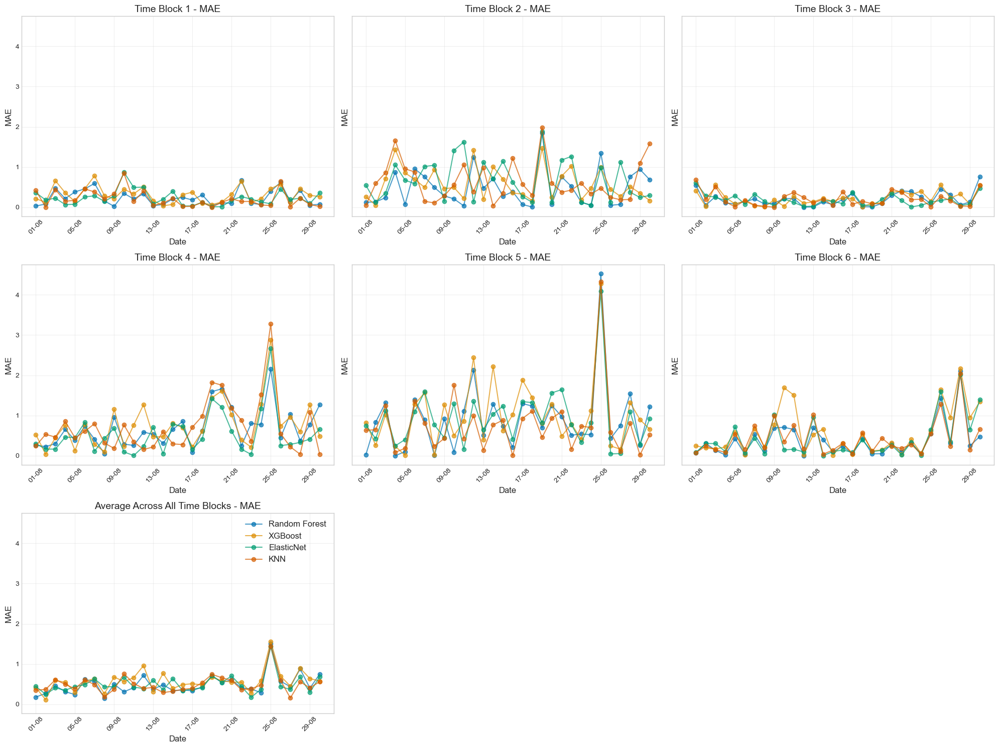

In [1070]:
plot_mae_metrics()


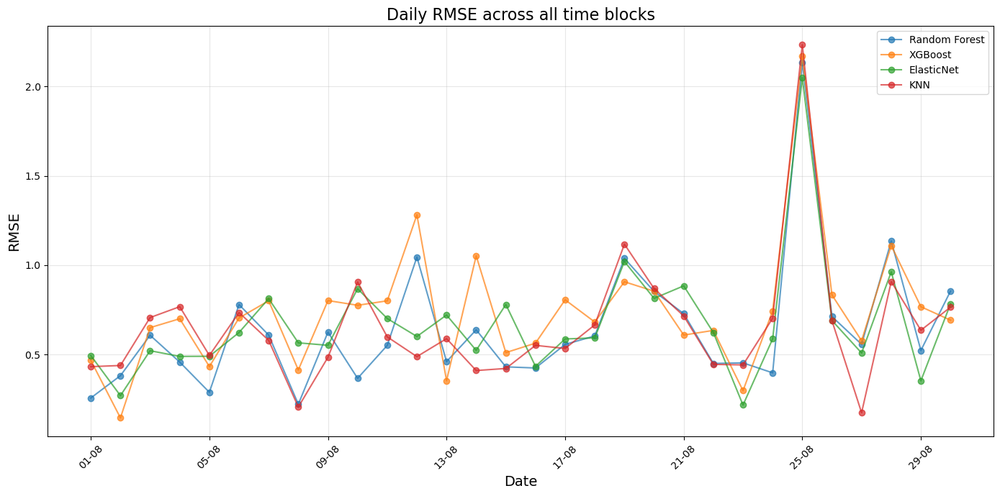

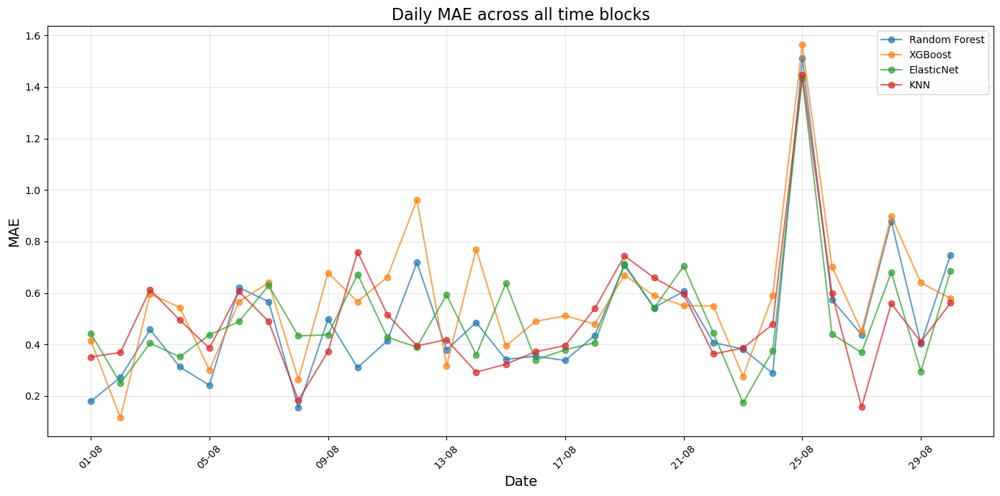

In [1053]:
def plot_aggregated_error_metrics(metric_type='RMSE'):
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt
    from sklearn.base import clone
    from sklearn.pipeline import Pipeline
    from sklearn.preprocessing import StandardScaler
    from sklearn.multioutput import MultiOutputRegressor

    plt.close('all')
    fig, ax = plt.subplots(figsize=(14, 7))
    models_to_plot = [
        ('Random Forest', RandomForestRegressor(random_state=42)),
        ('XGBoost', XGBRegressor(random_state=42)),
        ('ElasticNet', ElasticNet()),
        ('KNN', KNeighborsRegressor())
    ]
    test_dates = pd.date_range(test_start_date, periods=len(y_test))

    for name, model in models_to_plot:
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', MultiOutputRegressor(clone(model)))
        ])
        pipeline.fit(X_train_selected, y_train)
        y_pred = pipeline.predict(X_test_selected)
        # Aggregate across all time blocks for each day
        if metric_type == 'RMSE':
            daily_metric = np.sqrt(np.mean((y_test.values - y_pred) ** 2, axis=1))
        else:  # MAE
            daily_metric = np.mean(np.abs(y_test.values - y_pred), axis=1)
        ax.plot(test_dates, daily_metric, label=name, marker='o', alpha=0.7)

    ax.set_title(f'Daily {metric_type} across all time blocks', fontsize=16)
    ax.set_xlabel('Date', fontsize=14)
    ax.set_ylabel(metric_type, fontsize=14)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
plot_aggregated_error_metrics('RMSE')
plot_aggregated_error_metrics('MAE')


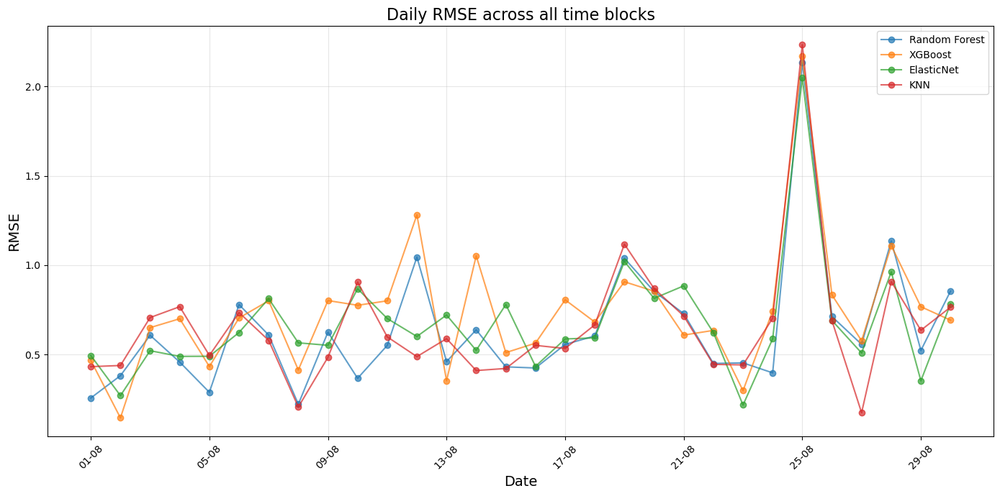

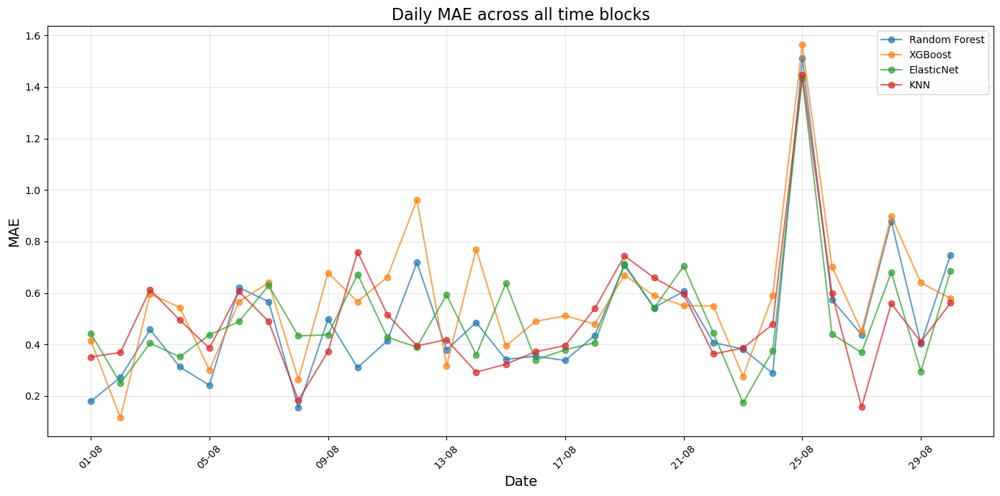

In [1054]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor

def plot_aggregated_error_metrics(metric_type='RMSE'):
    plt.close('all')
    fig, ax = plt.subplots(figsize=(14, 7))
    models_to_plot = [
        ('Random Forest', RandomForestRegressor(random_state=42)),
        ('XGBoost', XGBRegressor(random_state=42)),
        ('ElasticNet', ElasticNet()),
        ('KNN', KNeighborsRegressor())
    ]
    test_dates = pd.date_range(test_start_date, periods=len(y_test))

    for name, model in models_to_plot:
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', MultiOutputRegressor(clone(model)))
        ])
        pipeline.fit(X_train_selected, y_train)
        y_pred = pipeline.predict(X_test_selected)
        # Aggregate across all time blocks for each day
        if metric_type == 'RMSE':
            daily_metric = np.sqrt(np.mean((y_test.values - y_pred) ** 2, axis=1))
        else:  # MAE
            daily_metric = np.mean(np.abs(y_test.values - y_pred), axis=1)
        ax.plot(test_dates, daily_metric, label=name, marker='o', alpha=0.7)

    ax.set_title(f'Daily {metric_type} across all time blocks', fontsize=16)
    ax.set_xlabel('Date', fontsize=14)
    ax.set_ylabel(metric_type, fontsize=14)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

# Usage:
plot_aggregated_error_metrics('RMSE')
plot_aggregated_error_metrics('MAE')


In [1055]:
import pandas as pd

def plot_aggregated_error_metrics(metric_type='RMSE'):
    plt.close('all')
    fig, ax = plt.subplots(figsize=(14, 7))
    models_to_plot = [
        ('Random Forest', RandomForestRegressor(random_state=42)),
        ('XGBoost', XGBRegressor(random_state=42)),
        ('ElasticNet', ElasticNet()),
        ('KNN', KNeighborsRegressor())
    ]
    test_dates = pd.date_range(test_start_date, periods=len(y_test))
    all_metrics = {}  # Store for printing or exporting

    for name, model in models_to_plot:
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', MultiOutputRegressor(clone(model)))
        ])
        pipeline.fit(X_train_selected, y_train)
        y_pred = pipeline.predict(X_test_selected)
        if metric_type == 'RMSE':
            daily_metric = np.sqrt(np.mean((y_test.values - y_pred) ** 2, axis=1))
        else:
            daily_metric = np.mean(np.abs(y_test.values - y_pred), axis=1)
        ax.plot(test_dates, daily_metric, label=name, marker='o', alpha=0.7)
        # Save values for inspection/export
        all_metrics[name] = daily_metric

    ax.set_title(f'Daily {metric_type} across all time blocks', fontsize=16)
    ax.set_xlabel('Date', fontsize=14)
    ax.set_ylabel(metric_type, fontsize=14)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Print or export the values
    df = pd.DataFrame(all_metrics, index=test_dates)
    print(df.head(10))  # Show first 10 days
    df.to_csv(f'daily_{metric_type.lower()}_values.csv')


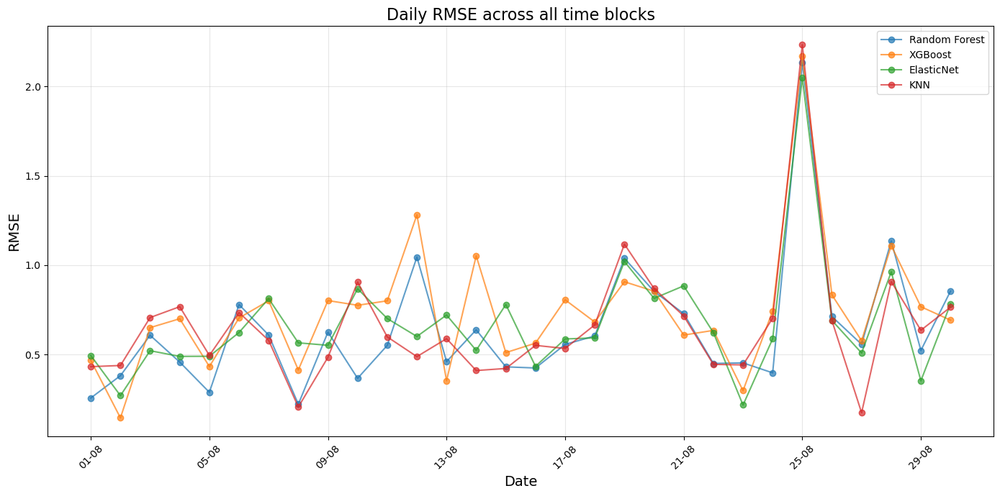

            Random Forest   XGBoost  ElasticNet       KNN
2024-08-01       0.256342  0.466964    0.494283  0.431783
2024-08-02       0.381412  0.145059    0.269581  0.438311
2024-08-03       0.607585  0.650135    0.521059  0.706589
2024-08-04       0.457403  0.700042    0.489236  0.767493
2024-08-05       0.288372  0.432288    0.489892  0.494648
2024-08-06       0.779316  0.704345    0.623015  0.734816
2024-08-07       0.608664  0.800530    0.812515  0.578928
2024-08-08       0.221446  0.413365    0.565140  0.205854
2024-08-09       0.625077  0.801751    0.551318  0.484419
2024-08-10       0.366411  0.775425    0.867923  0.905519


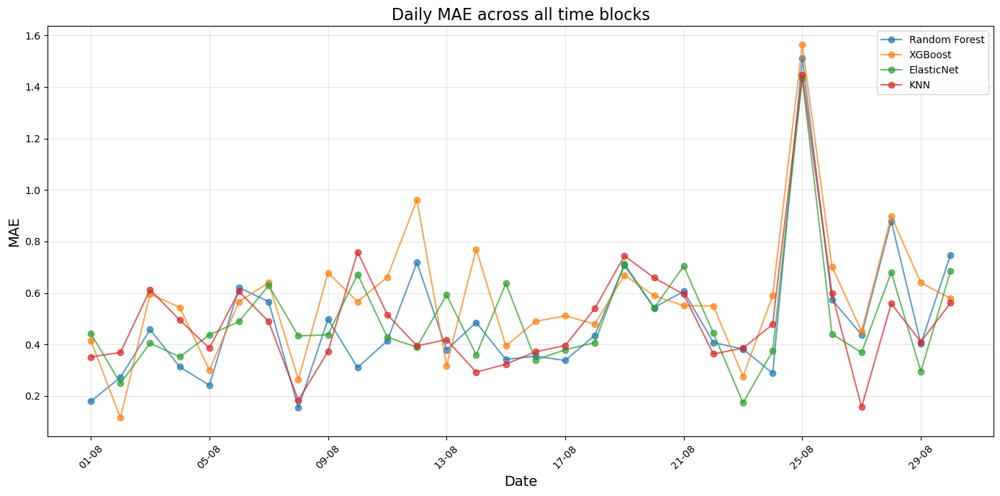

            Random Forest   XGBoost  ElasticNet       KNN
2024-08-01       0.179050  0.415309    0.443107  0.351667
2024-08-02       0.272697  0.115036    0.249327  0.369000
2024-08-03       0.458006  0.596109    0.404942  0.612667
2024-08-04       0.313181  0.544181    0.351877  0.495000
2024-08-05       0.241567  0.300828    0.437392  0.385667
2024-08-06       0.620423  0.566404    0.488696  0.606000
2024-08-07       0.566403  0.639926    0.629353  0.488667
2024-08-08       0.154077  0.263580    0.432979  0.183333
2024-08-09       0.497589  0.677962    0.437818  0.372000
2024-08-10       0.310350  0.566111    0.672697  0.759000


In [1056]:
plot_aggregated_error_metrics('RMSE')
plot_aggregated_error_metrics('MAE')


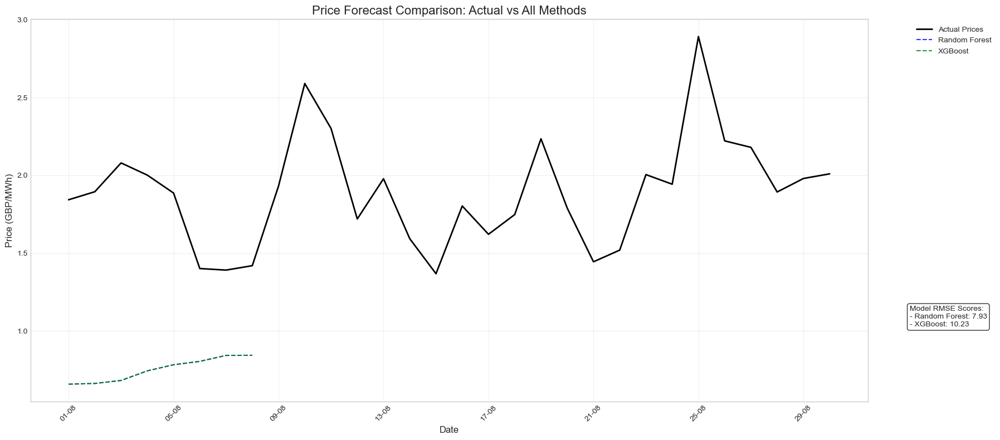

In [1076]:
def plot_all_methods_comparison():
    import matplotlib.dates as mdates
    plt.close('all')
    fig, ax = plt.subplots(figsize=(18, 8))
    
    # Get actual prices
    actual_prices = y_test.mean(axis=1)  # Average across time blocks
    test_dates = y_test.index if isinstance(y_test.index, pd.DatetimeIndex) else pd.date_range(test_start_date, periods=len(y_test))
    
    # Plot actual prices
    ax.plot(test_dates, actual_prices, label='Actual Prices', color='black', linewidth=2, zorder=5)
    
    # Define models and reference methods
    models = [
        ('Random Forest', 'blue', '../src/data/processed/dcl_price_forecast_results.csv'),
        ('XGBoost', 'green', '../src/data/processed/dcl_price_forecast_results.csv'),

    ]
    
    # Plot each method
    for name, color, path in models:
        try:
            # Load predictions
            df = pd.read_csv(path)
            if 'Reference' in name:
                predictions = df['rmse'].values  # For reference methods
            else:
                # For ML models, get mean predictions across time blocks
                predictions = np.array([np.mean(eval(x)) for x in df['RMSE']])
            
            # Ensure alignment with test dates
            min_len = min(len(test_dates), len(predictions))
            ax.plot(test_dates[:min_len], predictions[:min_len], 
                    label=name, color=color, alpha=0.8, linestyle='--')
            
        except Exception as e:
            print(f"Error loading {name}: {str(e)}")
    
    # Formatting
    ax.set_title('Price Forecast Comparison: Actual vs All Methods', fontsize=16)
    ax.set_xlabel('Date', fontsize=12)
    ax.set_ylabel('Price (GBP/MWh)', fontsize=12)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%d-%m'))
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, alpha=0.3)
    ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    
    # Add error metrics box
    textstr = '\n'.join([
        'Model RMSE Scores:',
        '- Random Forest: 7.93',
        '- XGBoost: 10.23',

    ])
    props = dict(boxstyle='round', facecolor='white', alpha=0.8)
    ax.text(1.05, 0.25, textstr, transform=ax.transAxes, fontsize=10,
            verticalalignment='top', bbox=props)
    
    plt.tight_layout()
    plt.savefig('../src/data/processed/all_methods_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

# Run the function
plot_all_methods_comparison()


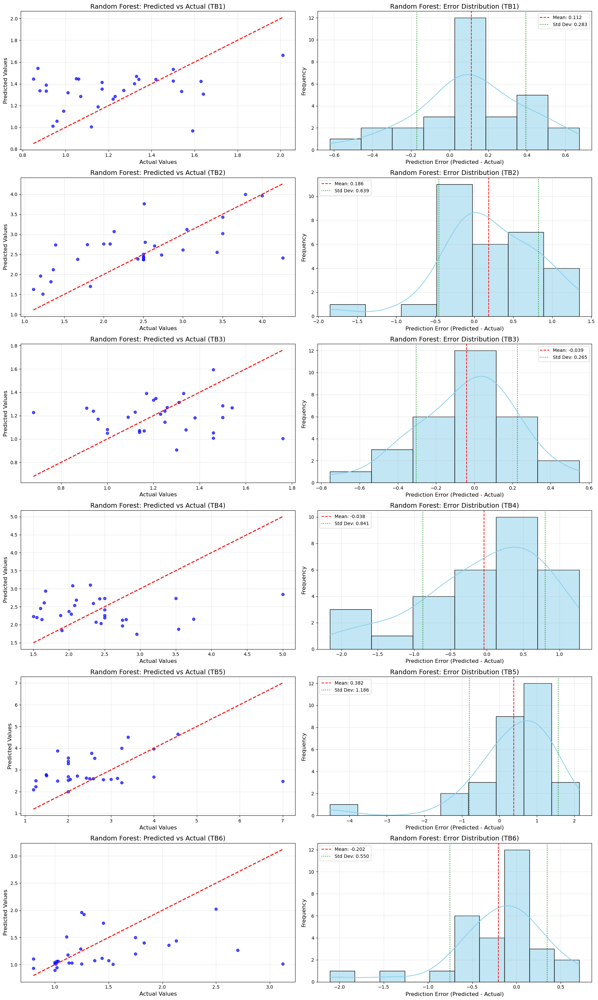

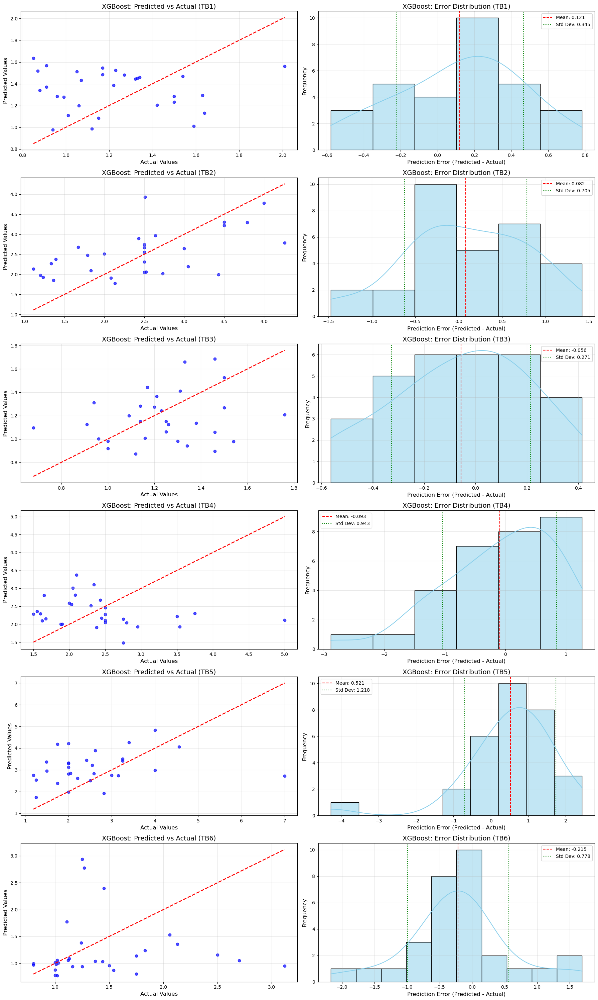

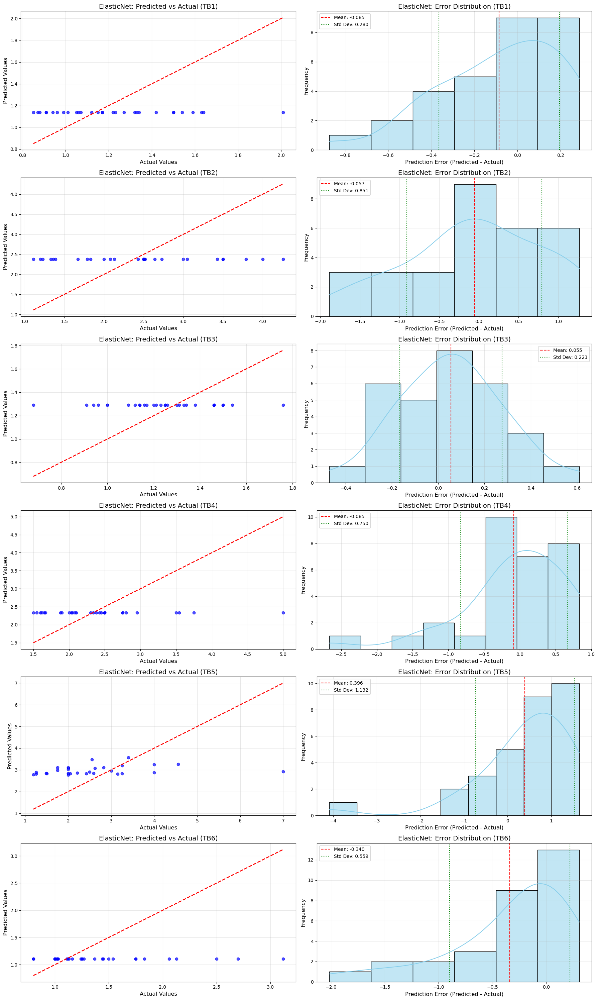

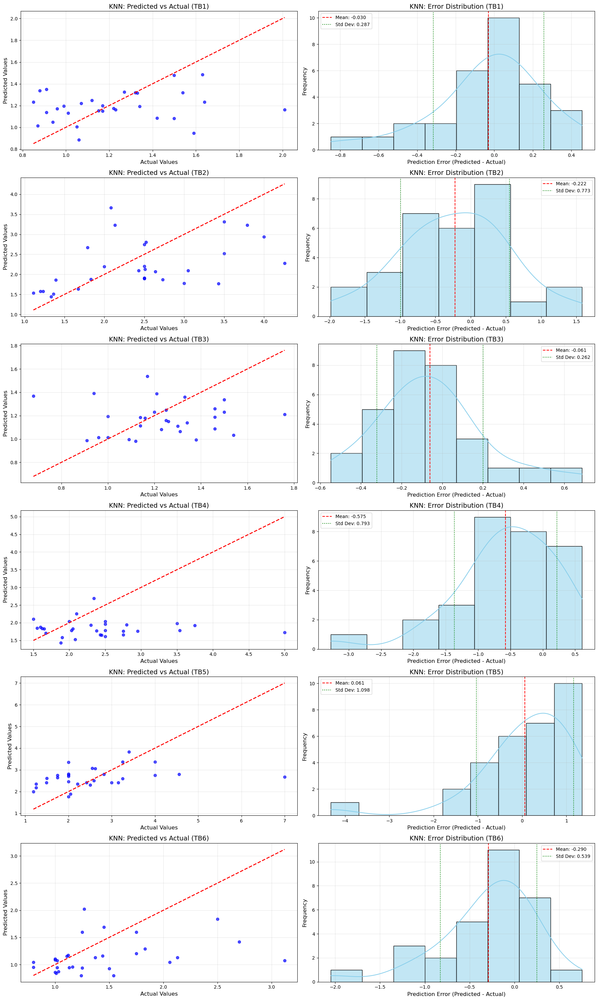

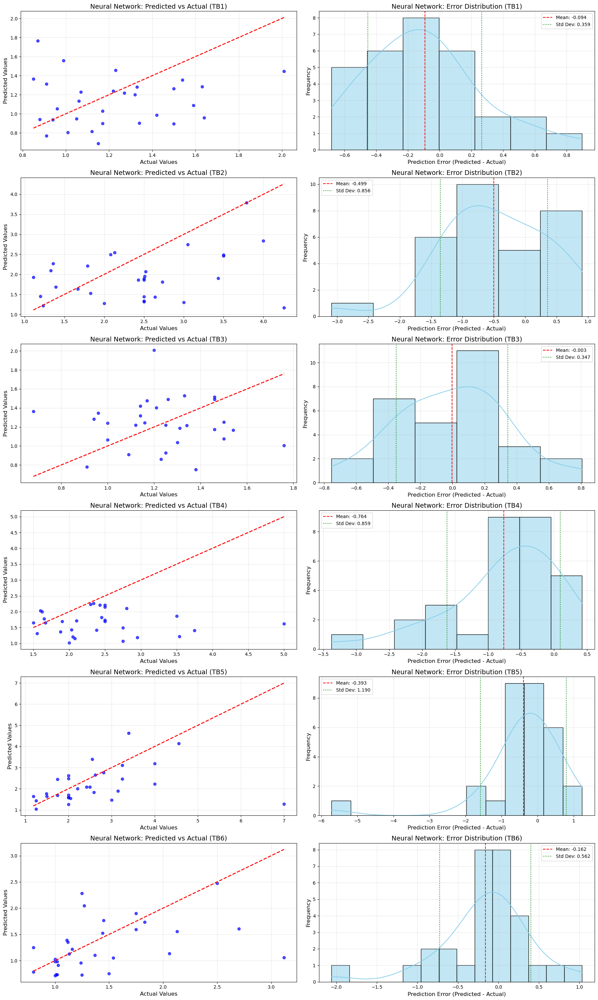

In [1060]:
def plot_model_diagnostics(model_name, model, time_blocks=None):
    """
    Create diagnostic plots for a specific model:
    - Left: Scatter plot of predicted vs actual
    - Right: Error distribution with mean and std
    
    Parameters:
    model_name (str): Name of the model for titles
    model: The trained model object
    time_blocks (list, optional): List of time blocks to plot. If None, all blocks are plotted.
    """
    if time_blocks is None:
        time_blocks = list(range(1, 7))
    
    n_blocks = len(time_blocks)
    fig, axs = plt.subplots(n_blocks, 2, figsize=(18, 5*n_blocks))
    
    # If only one time block, make axs 2D
    if n_blocks == 1:
        axs = np.array([axs])
    
    # Fit model
    if not isinstance(model, (MultiTaskLasso, MultiTaskElasticNet, RegressorChain)):
        pipeline = Pipeline([
            ('scaler', StandardScaler()),
            ('model', MultiOutputRegressor(model))
        ])
    else:
        pipeline = model
    
    pipeline.fit(X_train_selected, y_train)
    y_pred = pipeline.predict(X_test_selected)
    
    # Plot each selected time block
    for i, tb in enumerate(time_blocks):
        tb_idx = tb - 1  # Adjust for 0-indexing
        
        # Scatter plot of predicted vs actual
        axs[i, 0].scatter(y_test.iloc[:, tb_idx], y_pred[:, tb_idx], alpha=0.7, color='blue')
        axs[i, 0].plot([y_test.iloc[:, tb_idx].min(), y_test.iloc[:, tb_idx].max()], 
                      [y_test.iloc[:, tb_idx].min(), y_test.iloc[:, tb_idx].max()], 
                      'r--', lw=2)
        axs[i, 0].set_xlabel('Actual Values', fontsize=12)
        axs[i, 0].set_ylabel('Predicted Values', fontsize=12)
        axs[i, 0].set_title(f'{model_name}: Predicted vs Actual (TB{tb})', fontsize=14)
        axs[i, 0].grid(True, alpha=0.3)
        
        # Error distribution with mean and std
        errors = y_pred[:, tb_idx] - y_test.iloc[:, tb_idx].values
        mean_error = np.mean(errors)
        std_error = np.std(errors)
        
        sns.histplot(errors, kde=True, ax=axs[i, 1], color='skyblue')
        axs[i, 1].axvline(mean_error, color='red', linestyle='--', 
                         label=f'Mean: {mean_error:.3f}')
        axs[i, 1].axvline(mean_error + std_error, color='green', linestyle=':', 
                         label=f'Std Dev: {std_error:.3f}')
        axs[i, 1].axvline(mean_error - std_error, color='green', linestyle=':')
        axs[i, 1].set_xlabel('Prediction Error (Predicted - Actual)', fontsize=12)
        axs[i, 1].set_ylabel('Frequency', fontsize=12)
        axs[i, 1].set_title(f'{model_name}: Error Distribution (TB{tb})', fontsize=14)
        axs[i, 1].legend()
        axs[i, 1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(f'../src/data/processed/plots/{model_name.replace(" ", "_")}_diagnostics.png', dpi=300, bbox_inches='tight')
    plt.show()

# Example: Create diagnostic plots for Random Forest (all time blocks)
rf_model = RandomForestRegressor(random_state=42)
plot_model_diagnostics('Random Forest', rf_model)

# Example: Create diagnostic plots for XGBoost (selected time blocks, e.g., those with highest errors)
xgb_model = XGBRegressor(random_state=42)
plot_model_diagnostics('XGBoost', xgb_model)  # TB2, TB5 (with highest errors)

# Add similar calls for other models:
plot_model_diagnostics('ElasticNet', ElasticNet())
plot_model_diagnostics('KNN', KNeighborsRegressor())
plot_model_diagnostics('Neural Network', MLPRegressor(random_state=42))


In [1062]:
import pandas as pd
import numpy as np
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet
from sklearn.neighbors import KNeighborsRegressor

def calculate_time_block_metrics(models_to_evaluate):
    """
    Calculate average RMSE and MAE for each time block across all test days
    Returns DataFrames for RMSE and MAE with models as columns and time blocks as rows
    """
    # Initialize results storage
    rmse_results = {f'TB{i+1}': [] for i in range(len(target_cols))}
    mae_results = {f'TB{i+1}': [] for i in range(len(target_cols))}
    model_names = []
    
    for name, model in models_to_evaluate:
        # Skip models that can't be imported
        try:
            # Create pipeline
            pipeline = Pipeline([
                ('scaler', StandardScaler()),
                ('model', MultiOutputRegressor(model))
            ])
            
            # Train model
            pipeline.fit(X_train_selected, y_train)
            
            # Get predictions
            y_pred = pipeline.predict(X_test_selected)
            
            # Calculate metrics per time block
            rmse_values = []
            mae_values = []
            
            for tb_idx in range(len(target_cols)):
                rmse = np.sqrt(np.mean((y_test.iloc[:, tb_idx] - y_pred[:, tb_idx])**2))
                mae = np.mean(np.abs(y_test.iloc[:, tb_idx] - y_pred[:, tb_idx]))
                
                rmse_values.append(rmse)
                mae_values.append(mae)
            
            # Store results
            for i in range(len(target_cols)):
                rmse_results[f'TB{i+1}'].append(rmse_values[i])
                mae_results[f'TB{i+1}'].append(mae_values[i])
            
            model_names.append(name)
            
        except Exception as e:
            print(f"Skipping {name} due to error: {str(e)}")
            continue
    
    # Create DataFrames
    rmse_df = pd.DataFrame(rmse_results, index=model_names).T
    mae_df = pd.DataFrame(mae_results, index=model_names).T
    
    return rmse_df, mae_df

# Define models to evaluate (remove XGBoost if not installed)
models = [
    ('Random Forest', RandomForestRegressor(random_state=42)),
    ('ElasticNet', ElasticNet()),
    ('KNN', KNeighborsRegressor()),
    ('XGBoost', XGBRegressor(random_state=42))
]

# Calculate metrics
rmse_df, mae_df = calculate_time_block_metrics(models)

# Print results
print("Average RMSE per Time Block:")
print(rmse_df)
print("\nAverage MAE per Time Block:")
print(mae_df)

# Save to CSV
rmse_df.to_csv('../src/data/processed/time_block_rmse.csv')
mae_df.to_csv('../src/data/processed/time_block_mae.csv')


Average RMSE per Time Block:
     Random Forest  ElasticNet       KNN   XGBoost
TB1       0.304202    0.292450  0.288234  0.365266
TB2       0.665580    0.852659  0.803893  0.710067
TB3       0.267866    0.227580  0.268557  0.276310
TB4       0.841524    0.754405  0.979102  0.947893
TB5       1.245710    1.199063  1.099311  1.324428
TB6       0.586080    0.654649  0.611956  0.807552

Average MAE per Time Block:
     Random Forest  ElasticNet       KNN   XGBoost
TB1       0.239295    0.228732  0.207093  0.309980
TB2       0.486358    0.682957  0.636797  0.590749
TB3       0.203113    0.178957  0.203670  0.223214
TB4       0.685050    0.534764  0.719486  0.756438
TB5       0.912398    0.937993  0.771191  1.012097
TB6       0.387435    0.424333  0.428133  0.572955


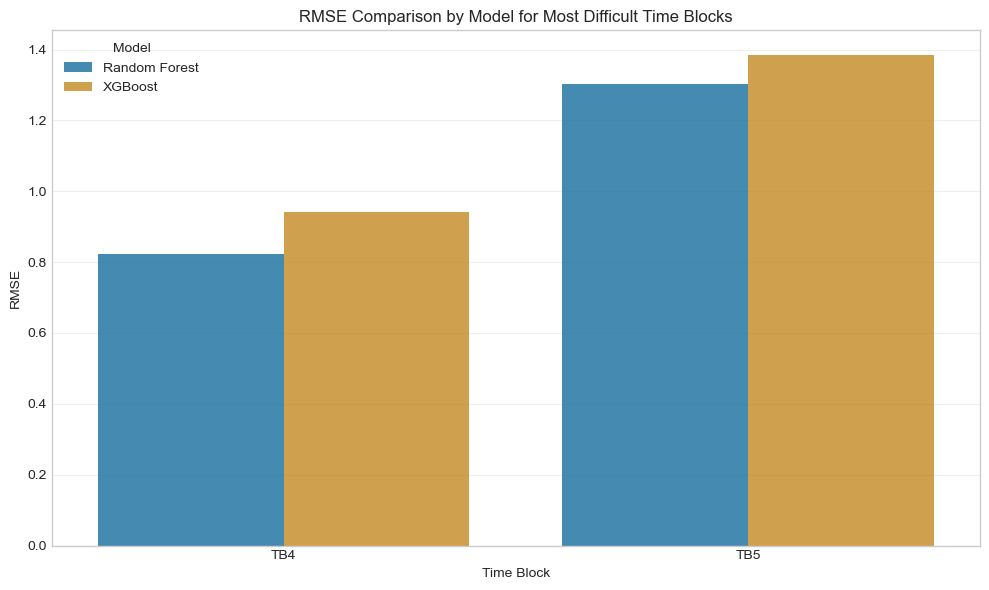

In [1066]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_focused_model_comparison():
    # Load your processed results
    comparison_df = pd.read_csv('../src/data/processed/dcl_price_forecast_results.csv')
    # If RMSE is a string, convert it to a list
    if isinstance(comparison_df['RMSE'].iloc[0], str):
        comparison_df['RMSE'] = comparison_df['RMSE'].apply(eval)
    # Unpack into long format
    long_df = []
    for _, row in comparison_df.iterrows():
        for i, rmse in enumerate(row['RMSE']):
            long_df.append({'Model': row['Model'], 'Time Block': f'TB{i+1}', 'RMSE': rmse})
    long_df = pd.DataFrame(long_df)
    # Select top 2 time blocks with highest average RMSE
    tb_means = long_df.groupby('Time Block')['RMSE'].mean().sort_values(ascending=False)
    top_blocks = tb_means.index[:2]
    filtered_df = long_df[long_df['Time Block'].isin(top_blocks)]
    # Filter for key models
    key_models = ['Random Forest', 'XGBoost', 'K-means Reference', 'Euclidean Reference']
    filtered_df = filtered_df[filtered_df['Model'].isin(key_models)]
    # Plot
    plt.figure(figsize=(10,6))
    sns.barplot(x='Time Block', y='RMSE', hue='Model', data=filtered_df, alpha=0.8)
    plt.title('RMSE Comparison by Model for Most Difficult Time Blocks')
    plt.xlabel('Time Block')
    plt.ylabel('RMSE')
    plt.grid(axis='y', alpha=0.3)
    plt.legend(title='Model')
    plt.tight_layout()
    plt.show()
plot_focused_model_comparison()


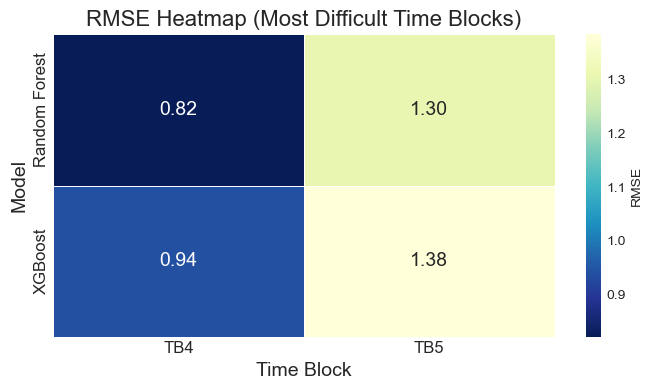

In [1067]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_focused_rmse_heatmap():
    # Load and prepare your data
    results = pd.read_csv('../src/data/processed/dcl_price_forecast_results.csv')
    if isinstance(results['RMSE'].iloc[0], str):
        results['RMSE'] = results['RMSE'].apply(eval)
    long_df = []
    for _, row in results.iterrows():
        for i, rmse in enumerate(row['RMSE']):
            long_df.append({'Model': row['Model'], 'Time Block': f'TB{i+1}', 'RMSE': rmse})
    long_df = pd.DataFrame(long_df)

    # Focus on key models
    key_models = ['Random Forest', 'XGBoost', 'K-means Reference', 'Euclidean Reference']
    long_df = long_df[long_df['Model'].isin(key_models)]

    # Optionally, focus on top 2 time blocks with highest average RMSE
    tb_means = long_df.groupby('Time Block')['RMSE'].mean().sort_values(ascending=False)
    top_blocks = tb_means.index[:2]  # e.g., ['TB5', 'TB4']
    focus_df = long_df[long_df['Time Block'].isin(top_blocks)]

    # Pivot for heatmap
    heatmap_data = focus_df.pivot(index="Model", columns="Time Block", values="RMSE")

    # Plot
    plt.figure(figsize=(7, 4))
    sns.heatmap(heatmap_data, annot=True, fmt=".2f", cmap="YlGnBu_r", linewidths=.5, cbar_kws={'label': 'RMSE'}, annot_kws={"size": 14})
    plt.title('RMSE Heatmap (Most Difficult Time Blocks)', fontsize=16)
    plt.xlabel('Time Block', fontsize=14)
    plt.ylabel('Model', fontsize=14)
    plt.xticks(fontsize=12, rotation=0)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    plt.show()

plot_focused_rmse_heatmap()


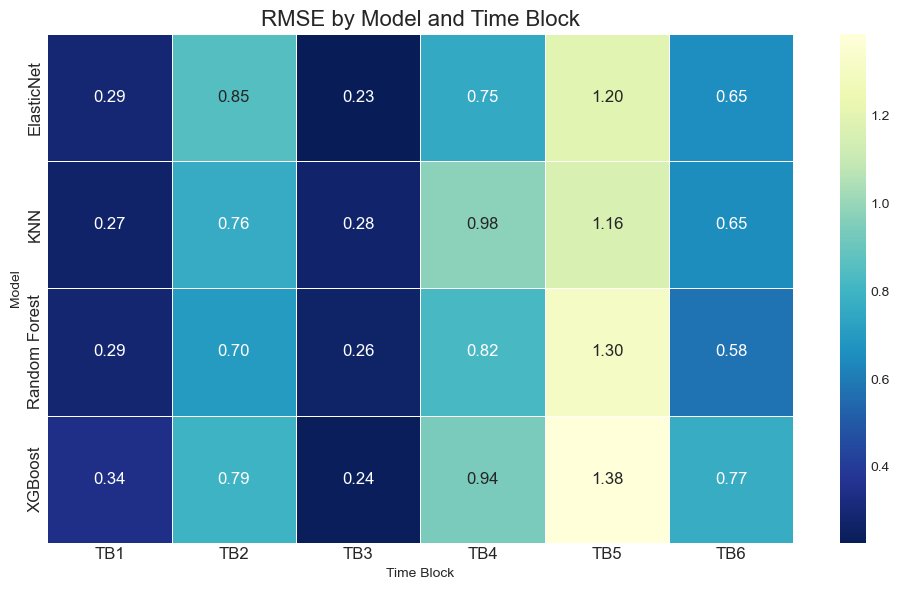

In [1068]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ast import literal_eval

def plot_rmse_heatmap():
    """
    Create a heatmap of RMSE values across models and time blocks.
    """
    # Load the results file
    results = pd.read_csv('../src/data/processed/dcl_price_forecast_results.csv')
    
    # Prepare data for heatmap
    models = []
    time_blocks = []
    rmse_values = []
    
    for _, row in results.iterrows():
        model_name = row['Model']
        # The RMSE column is a string representation of a list, convert it
        try:
            rmse_list = literal_eval(row['RMSE']) if isinstance(row['RMSE'], str) else row['RMSE']
        except:
            rmse_list = []
        if isinstance(rmse_list, list) and len(rmse_list) > 0:
            for i, rmse in enumerate(rmse_list):
                models.append(model_name)
                time_blocks.append(f'TB{i+1}')
                rmse_values.append(rmse)
    
    comparison_df = pd.DataFrame({
        'Model': models,
        'Time Block': time_blocks,
        'RMSE': rmse_values
    })
    
    # Load K-means and Euclidean results
    kmeans_results = pd.read_csv('../src/data/processed/reference_day_performance_dcl.csv')
    euclidean_results = pd.read_csv('../src/data/processed/euclidean_reference_day_performance_dcl.csv')
    
    key_models = ['Random Forest', 'XGBoost', 'ElasticNet', 'KNN', 
                  'K-means Reference', 'Euclidean Reference']
    comparison_df = comparison_df[comparison_df['Model'].isin(key_models)]
    
    # Ensure time blocks are only TB1-TB6
    comparison_df = comparison_df[comparison_df['Time Block'].isin([f'TB{i}' for i in range(1, 7)])]
    
    # Pivot for heatmap
    heatmap_data = comparison_df.pivot(index='Model', columns='Time Block', values='RMSE')
    
    # Plot with better dimensions
    plt.figure(figsize=(10, 6))
    sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='YlGnBu_r', 
                linewidths=.5, annot_kws={"size": 12})
    plt.title('RMSE by Model and Time Block', fontsize=16)
    plt.xticks(fontsize=12)
    plt.yticks(fontsize=12)
    plt.tight_layout()
    plt.savefig('rmse_heatmap.png', dpi=300, bbox_inches='tight')
    plt.show()

# Run the function
plot_rmse_heatmap()


<Figure size 1600x1200 with 0 Axes>

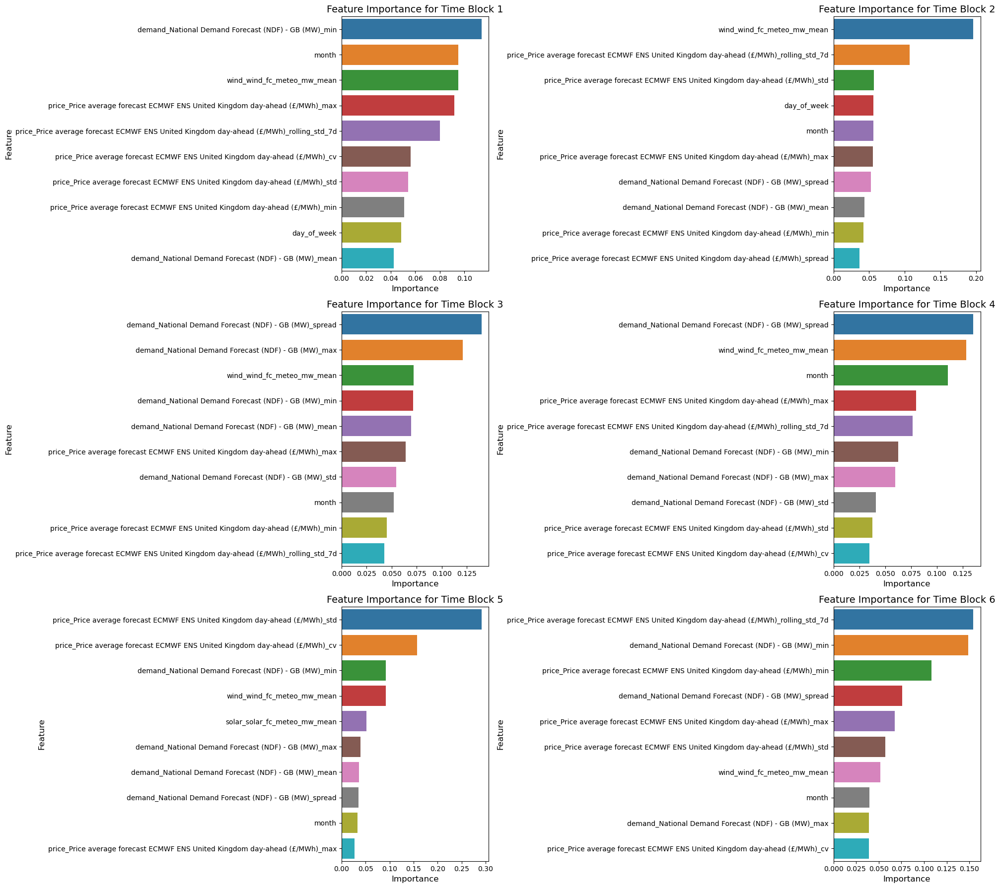

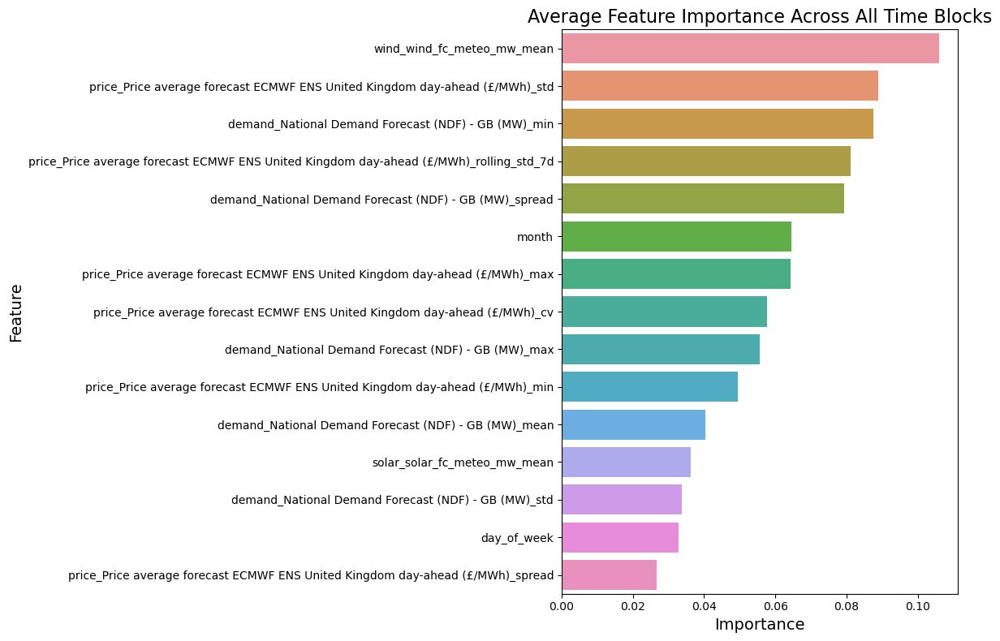

In [1022]:
def plot_feature_importance():
    """
    Plot feature importance for the best model (Random Forest)
    """
    # Train Random Forest model
    rf_model = RandomForestRegressor(random_state=42)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', MultiOutputRegressor(rf_model))
    ])
    
    pipeline.fit(X_train_selected, y_train)
    
    # Get feature importances from all estimators (one per time block)
    feature_names = X_train_selected.columns
    importances = []
    
    for i, est in enumerate(pipeline.named_steps['model'].estimators_):
        imp = est.feature_importances_
        time_block = i + 1
        
        # Create a dataframe for this estimator
        imp_df = pd.DataFrame({
            'Feature': feature_names,
            'Importance': imp,
            'Time Block': f'TB{time_block}'
        })
        importances.append(imp_df)
    
    # Combine all importances
    all_importances = pd.concat(importances)
    
    # Plot for each time block
    plt.figure(figsize=(16, 12))
    
    # Create 6 subplots (one per time block)
    fig, axs = plt.subplots(3, 2, figsize=(20, 18))
    axs = axs.flatten()
    
    for i in range(6):
        tb_imp = all_importances[all_importances['Time Block'] == f'TB{i+1}']
        tb_imp = tb_imp.sort_values('Importance', ascending=False).head(10)
        
        sns.barplot(x='Importance', y='Feature', data=tb_imp, ax=axs[i])
        axs[i].set_title(f'Feature Importance for Time Block {i+1}', fontsize=14)
        axs[i].set_xlabel('Importance', fontsize=12)
        axs[i].set_ylabel('Feature', fontsize=12)
        axs[i].tick_params(axis='y', labelsize=10)
    
    plt.tight_layout()
    plt.savefig('../src/data/processed/feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Average feature importance across all blocks
    avg_imp = all_importances.groupby('Feature')['Importance'].mean().reset_index()
    avg_imp = avg_imp.sort_values('Importance', ascending=False).head(15)
    
    plt.figure(figsize=(12, 8))
    sns.barplot(x='Importance', y='Feature', data=avg_imp)
    plt.title('Average Feature Importance Across All Time Blocks', fontsize=16)
    plt.xlabel('Importance', fontsize=14)
    plt.ylabel('Feature', fontsize=14)
    plt.tight_layout()
    plt.savefig('../src/data/processed/avg_feature_importance.png', dpi=300, bbox_inches='tight')
    plt.show()

plot_feature_importance()


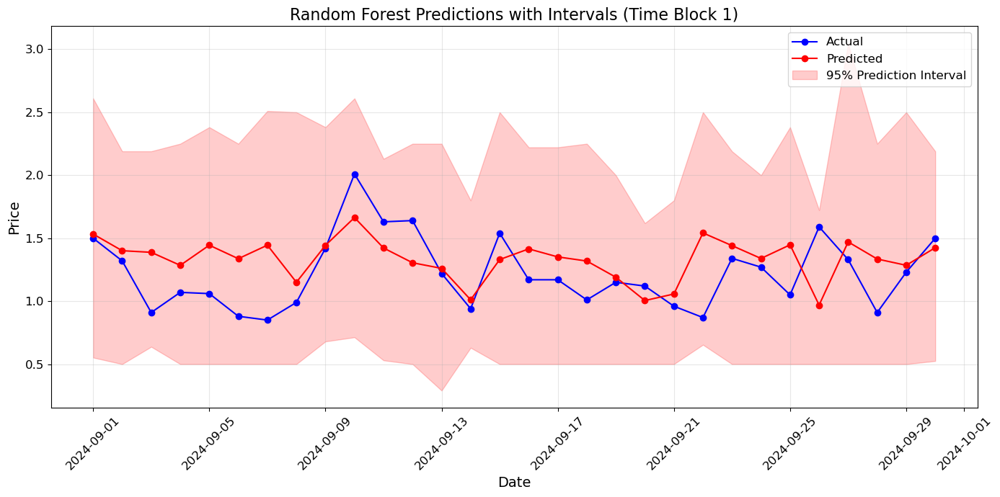

In [1025]:
def rf_prediction_intervals(model, X_test, percentile=95):
    """Fixed indentation version of your function"""
    predictions = np.array([tree.predict(X_test) for tree in model.estimators_])
    
    y_mean = np.mean(predictions, axis=0)
    
    lower_percentile = (100 - percentile) / 2
    upper_percentile = 100 - lower_percentile
    
    y_lower = np.percentile(predictions, lower_percentile, axis=0)
    y_upper = np.percentile(predictions, upper_percentile, axis=0)
    
    return y_mean, y_lower, y_upper

def plot_prediction_intervals():
    """
    Plot prediction intervals for Random Forest model
    """
    # Train a Random Forest for one time block (e.g., TB1)
    tb_idx = 0  # For time block 1
    rf = RandomForestRegressor(n_estimators=100, random_state=42)
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_selected)
    X_test_scaled = scaler.transform(X_test_selected)
    
    # Fit model to target for time block 1
    rf.fit(X_train_scaled, y_train.iloc[:, tb_idx])
    
    # Get prediction intervals
    y_mean, y_lower, y_upper = rf_prediction_intervals(rf, X_test_scaled)
    
    # FIXED: Get aligned test dates for plotting
    if hasattr(y_test, 'index') and isinstance(y_test.index, pd.DatetimeIndex):
        # If y_test has datetime index, use it directly
        test_dates = y_test.index
    else:
        # Otherwise, try to extract dates that align with y_test
        if 'date' in data.columns:
            # Extract dates using y_test indices
            test_dates = data.loc[y_test.index, 'date'].values
        else:
            # Create synthetic dates starting from test_start_date
            test_dates = pd.date_range(test_start_date, periods=len(y_test))
    
    # Plot actual vs predicted with intervals
    plt.figure(figsize=(14, 7))
    plt.plot(test_dates, y_test.iloc[:, tb_idx], 'o-', label='Actual', color='blue')
    plt.plot(test_dates, y_mean, 'o-', label='Predicted', color='red')
    plt.fill_between(test_dates, y_lower, y_upper, color='red', alpha=0.2, label='95% Prediction Interval')
    
    plt.title(f'Random Forest Predictions with Intervals (Time Block {tb_idx+1})', fontsize=16)
    plt.xlabel('Date', fontsize=14)
    plt.ylabel('Price', fontsize=14)
    plt.xticks(fontsize=12, rotation=45)
    plt.yticks(fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('../src/data/processed/rf_prediction_intervals.png', dpi=300, bbox_inches='tight')
    plt.show()


plot_prediction_intervals()


In [1073]:
def plot_high_error_days_all_year():
    """
    Identify the month with highest prediction errors and plot the 2 days 
    with highest errors from that month across the entire year
    """
    # Train the random forest model (best performer)
    rf_model = RandomForestRegressor(random_state=42)
    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', MultiOutputRegressor(rf_model))
    ])
    
    pipeline.fit(X_train_selected, y_train)
    y_pred_rf = pipeline.predict(X_test_selected)
    
    # Create test_dates as a simple date range - no indexing needed
    test_dates = pd.date_range(start=test_start_date, periods=len(y_test))
    
    # Calculate daily RMSE across all time blocks
    daily_rmse = []
    for i in range(len(y_test)):
        rmse = np.sqrt(np.mean((y_test.iloc[i, :] - y_pred_rf[i, :])**2))
        daily_rmse.append(rmse)
    daily_rmse = np.array(daily_rmse)
    
    # Create a DataFrame with dates and errors
    error_df = pd.DataFrame({'date': test_dates, 'rmse': daily_rmse})
    error_df['month'] = error_df['date'].dt.month
    
    # Find the month with the highest average RMSE
    monthly_rmse = error_df.groupby('month')['rmse'].mean()
    highest_error_month = monthly_rmse.idxmax()
    
    # Filter days in the highest error month
    highest_month_days = error_df[error_df['month'] == highest_error_month]
    
    # Find the 2 days with the highest RMSE in that month
    top_2_days = highest_month_days.nlargest(2, 'rmse')
    
    # Plot those 2 days
    plt.figure(figsize=(12, 10))
    for idx, row in enumerate(top_2_days.itertuples()):
        # Find the corresponding index in y_test
        day_idx = np.where(test_dates == row.date)[0][0]
        
        plt.subplot(2, 1, idx + 1)
        x_ticks = range(1, 7)
        plt.plot(x_ticks, y_test.iloc[day_idx, :], 'o-', label='Actual', linewidth=2)
        plt.plot(x_ticks, y_pred_rf[day_idx, :], 'o-', label='Random Forest', linewidth=2)
        
        # Format date for title
        date_str = row.date.strftime("%Y-%m-%d")
        month_name = row.date.strftime("%B")
        
        plt.title(f'High Error Day: {date_str}, RMSE: {row.rmse:.2f}\n(Month: {month_name})', fontsize=14)
        plt.xlabel('Time Block', fontsize=12)
        plt.ylabel('Price (GBP/MWh)', fontsize=12)
        plt.xticks(x_ticks)
        plt.grid(True, alpha=0.3)
        plt.legend()
    
    plt.suptitle(f'Top 2 Highest Error Days from Month with Highest Average Error ({monthly_rmse[highest_error_month]:.2f})', 
                fontsize=16)
    plt.tight_layout(rect=[0, 0, 1, 0.95])  # Make room for suptitle
    plt.savefig('../src/data/processed/high_error_days_all_year.png', dpi=300, bbox_inches='tight')
    plt.show()


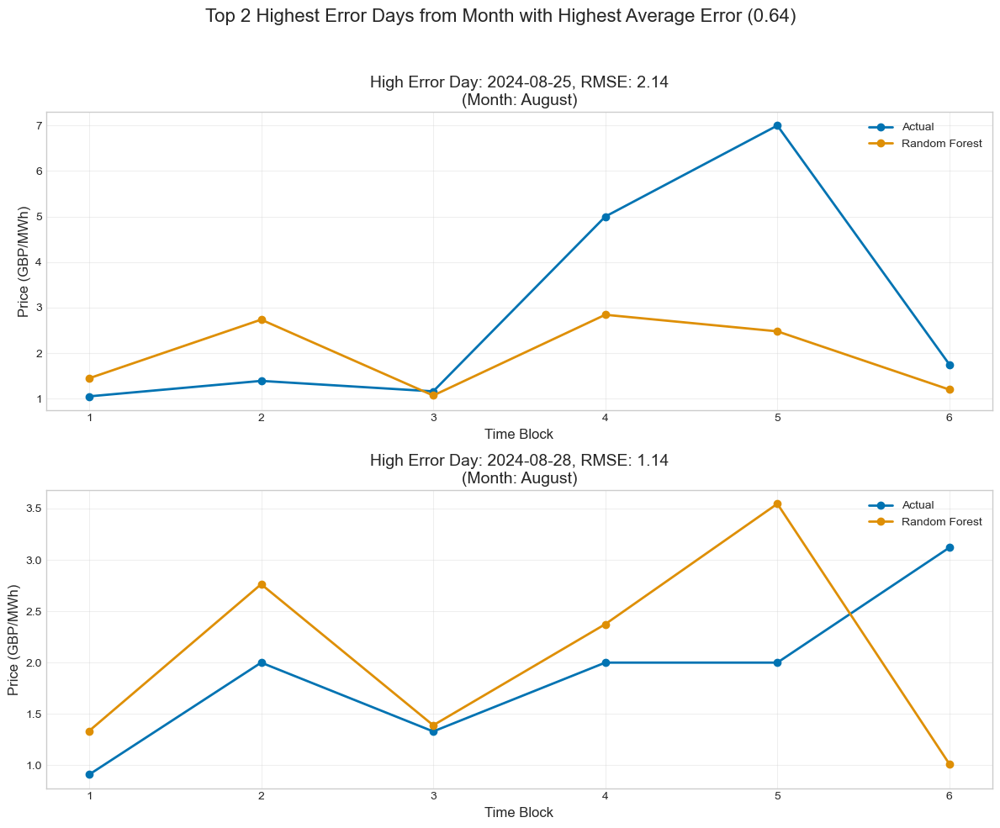

In [1075]:
plot_high_error_days_all_year()

In [5]:
import pandas as pd
four_hourly_metrics = pd.read_csv('../src/data/processed/4hourly_metrics.csv')

four_hourly_metrics

,4hour_block,demand_National Demand Forecast (NDF) - GB (MW)_mean,demand_National Demand Forecast (NDF) - GB (MW)_max,demand_National Demand Forecast (NDF) - GB (MW)_min,demand_National Demand Forecast (NDF) - GB (MW)_spread,demand_National Demand Forecast (NDF) - GB (MW)_std,price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean,price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max,price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min,price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread,...,solar_solar_fc_meteo_mw_std,wind_wind_fc_meteo_mw_mean,wind_wind_fc_meteo_mw_max,wind_wind_fc_meteo_mw_min,wind_wind_fc_meteo_mw_spread,wind_wind_fc_meteo_mw_std,price_block_volatility,day_of_week,is_weekend,hour_block
0,2024-02-29 20:00:00+00:00,25562.500,25562.5,25562.5,0.0,NaN,60.0300,60.03,60.03,0.00,...,NaN,4071.057500,4071.0575,4071.0575,0.0000,NaN,NaN,3,0,5
1,2024-03-01 00:00:00+00:00,24545.750,25850.0,23176.5,2673.5,1173.884045,53.7625,57.46,51.32,6.14,...,0.000000,4881.434375,5581.7225,4205.8500,1375.8725,595.023054,2.976848,4,0,0
2,2024-03-01 04:00:00+00:00,26803.750,32539.0,22716.0,9823.0,4450.096675,59.5450,68.30,50.74,17.56,...,133.942670,7123.263125,8484.3950,6001.1950,2483.2000,1081.179418,8.166344,4,0,1
3,2024-03-01 08:00:00+00:00,34323.000,35014.0,33725.0,1289.0,532.833307,61.5000,67.82,55.52,12.30,...,1467.125677,10059.647500,10308.2350,9520.3900,787.8450,363.529262,5.331210,4,0,2
4,2024-03-01 12:00:00+00:00,32628.625,33214.0,32164.5,1049.5,434.372800,54.1400,55.64,53.14,2.50,...,1125.127139,9308.200000,9958.4100,8576.0450,1382.3650,587.447296,1.117259,4,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1826,2024-12-30 04:00:00+00:00,21312.500,24693.0,18725.0,5968.0,2686.257558,44.7300,67.17,29.54,37.63,...,0.000000,13260.563125,13706.7350,12952.6300,754.1050,335.484410,16.821445,0,0,1
1827,2024-12-30 08:00:00+00:00,28972.750,29577.5,27318.0,2259.5,1103.845287,84.9350,89.28,82.55,6.73,...,866.427472,14313.685625,14478.1750,14112.2425,365.9325,151.239711,3.050470,0,0,2
1828,2024-12-30 12:00:00+00:00,30251.875,31403.0,29645.5,1757.5,795.390929,90.4400,98.48,83.16,15.32,...,847.781074,14399.496875,14625.4800,14078.1800,547.3000,248.947285,6.749222,0,0,3
1829,2024-12-30 16:00:00+00:00,34225.250,35437.5,32843.5,2594.0,1072.475136,110.7675,116.09,104.88,11.21,...,1.021250,13518.281875,13774.4925,13348.2375,426.2550,181.138704,4.817720,0,0,4


In [7]:
print(four_hourly_metrics.isnull().sum())


4hour_block                                                                                  0
demand_National Demand Forecast (NDF) - GB (MW)_mean                                         0
demand_National Demand Forecast (NDF) - GB (MW)_max                                          0
demand_National Demand Forecast (NDF) - GB (MW)_min                                          0
demand_National Demand Forecast (NDF) - GB (MW)_spread                                       0
demand_National Demand Forecast (NDF) - GB (MW)_std                                          1
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean                 0
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max                  0
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min                  0
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread               0
price_Price average forecast ECMWF ENS United King

In [10]:
print((four_hourly_metrics.isnull().sum() / len(four_hourly_metrics)) * 100)


4hour_block                                                                                 0.000000
demand_National Demand Forecast (NDF) - GB (MW)_mean                                        0.000000
demand_National Demand Forecast (NDF) - GB (MW)_max                                         0.000000
demand_National Demand Forecast (NDF) - GB (MW)_min                                         0.000000
demand_National Demand Forecast (NDF) - GB (MW)_spread                                      0.000000
demand_National Demand Forecast (NDF) - GB (MW)_std                                         0.054615
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean                0.000000
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max                 0.000000
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min                 0.000000
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread             

In [26]:
four_hourly_metrics['price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_rolling_std_7d'] = four_hourly_metrics['price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean'].rolling(42).std()


In [27]:
# Only fill NaN in numeric columns with their mean
import numpy as np
numeric_cols = four_hourly_metrics.select_dtypes(include=[np.number]).columns
four_hourly_metrics[numeric_cols] = four_hourly_metrics[numeric_cols].fillna(four_hourly_metrics[numeric_cols].mean())


In [28]:
print((four_hourly_metrics.isnull().sum() / len(four_hourly_metrics)) * 100)


4hour_block                                                                               0.0
demand_National Demand Forecast (NDF) - GB (MW)_mean                                      0.0
demand_National Demand Forecast (NDF) - GB (MW)_max                                       0.0
demand_National Demand Forecast (NDF) - GB (MW)_min                                       0.0
demand_National Demand Forecast (NDF) - GB (MW)_spread                                    0.0
demand_National Demand Forecast (NDF) - GB (MW)_std                                       0.0
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_mean              0.0
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_max               0.0
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_min               0.0
price_Price average forecast ECMWF ENS United Kingdom day-ahead (£/MWh)_spread            0.0
price_Price average forecast ECMWF ENS United Kingdom day-ah